# 06 · Model Evaluation
### BNI Ecosystem & Growth Intelligence — Kelompok 8 · ODP BNI Data Analytics Batch 2

| # | Notebook | Isi |
|---|---|---|
| 04 | Modelling | baseline, OOF, aturan anomali, skor v0 |
| 05 | Modelling Optimization | perbaikan LR, HPO, imbalance, ensemble, kalibrasi, conformal |
| **06** | **Model Evaluation** | **notebook ini — champion final, kunci evaluasi, penilaian SEKALI di test & ground truth, dampak bisnis, kartu model, skor v2** |
| 07 | Post-evaluation & Remodelling | analisis kesalahan mendalam (pasca-evaluasi) |
| 08 | Segmentasi & Opportunity Score | K-means 3 segmen, skor per segmen |

## Prinsip
NB06 adalah **satu-satunya** notebook yang membuka label test (200 nasabah kredit) dan ground truth (`eval_targets/`). Urutannya:
1. **Bagian B — finalisasi champion** memakai data dev saja: XGBoost hasil tuning NB05, skema bobot kelas, kalibrasi, ambang, conformal, versi non-kredit & prospect, SHAP, dan aturan anomali.
2. **Bagian C — kunci evaluasi**: hash semua file model + aturan keputusan ditulis ke `evaluation_lock.json`.
3. **Bagian D–J — penilaian sekali**: label dibuka. Tidak ada lagi perubahan model atau ambang; kesalahan menjadi bahan NB07.

## Keputusan yang dipakai (11 Okt)
- **Champion risiko = XGBoost ordinal monoton hasil tuning (M3_t)**. NB05 tidak dijalankan ulang; dasar keputusan: K2 dinilai di titik operasi + aturan seri ke model yang lebih sederhana.
- **Pembanding di test = champion yang tersimpan di `models/05_optimization/`** (LR NB04 terkalibrasi). Hanya dua model ini yang dinilai di test.
- **Anomali**: aturan NB04 dibekukan (`anomaly_rules.json`); challenger skor gabungan & **Isolation Forest** sebagai pembanding shadow.
- **Dampak bisnis**: asumsi di sel konfigurasi, diuji sensitivitasnya ±20%.

**Daftar isi:** A. Setup · B. Finalisasi champion (sebelum kunci) · C. Kunci evaluasi · D. Kinerja risiko di test · E. Kalibrasi & conformal di test · F. Label berisik · G. Prospect & non-kredit · H. Anomali · I. Dampak bisnis · J. Analisis kesalahan · K. Skor v2, kartu model, ringkasan · Daftar pustaka

## A. Setup
**Konfigurasi** (sel berikut): target recall, α conformal, asumsi dampak bisnis, k anomali. Ubah di sini **sebelum** menjalankan; setelah bagian C nilainya terkunci.

In [1]:
import hashlib, json, shutil, sys, time, warnings
from datetime import datetime
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
import joblib
import sklearn
from scipy import stats
from threadpoolctl import threadpool_limits
from sklearn.ensemble import IsolationForest
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, confusion_matrix
from sklearn.model_selection import StratifiedGroupKFold, StratifiedKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

try:
    import xgboost as xgb; HAS_XGB = True
except ImportError:
    HAS_XGB = False
try:
    import lightgbm as lgb; HAS_LGB = True
except ImportError:
    HAS_LGB = False

warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', 40); pd.set_option('display.width', 200); pd.set_option('display.max_colwidth', 90)
threadpool_limits(1)
SEED = 2026; T0 = time.time()

# ---- konfigurasi (dikunci di bagian C) ----
TARGET_RECALL = 0.90                 # recall High minimum (lapis 3)
ALPHA = 0.10                         # conformal: cakupan target 90%
N_BOOT = 2000
REPRO_TOL = 0.01                     # toleransi cek reproduksi log-loss OOF champion vs NB05
CAL_METHOD = 'temperature+prior'     # metode kalibrasi terpilih NB05 untuk semua kandidat
IW_POWER, IW_CLIP = 0.5, (0.1, 10.0) # importance weighting prospect (sama dengan NB05)
K_TOP = 30                           # kapasitas RM: alarm per bulan untuk ±1.200 nasabah non-test
ASSUMPTIONS = {                      # dampak bisnis — asumsi ilustratif, perlu disepakati tim
    'PD_Low': 0.01, 'PD_Medium': 0.05, 'PD_High': 0.20,   # probabilitas gagal 12 bln per kelas sebenarnya
    'LGD': 0.45,                                           # gaya nilai supervisi F-IRB (BCBS CRE32) untuk senior tanpa jaminan
    'mitigasi': 0.30,                                      # % kerugian yang dicegah bila High terdeteksi dini
    'biaya_review_Rp_juta': 2.0,                           # biaya review analis per kasus yang di-flag
}
RUN_ISOLATION_FOREST = True

In [2]:
def find_root(start=Path.cwd()):
    for p in [start, *start.parents]:
        if (p / 'pyproject.toml').exists(): return p
    raise FileNotFoundError('pyproject.toml tidak ditemukan — jalankan notebook dari dalam folder proyek')

PROJECT_ROOT = find_root()
SRC, PROC, RAW = PROJECT_ROOT / 'src', PROJECT_ROOT / 'data' / 'processed', PROJECT_ROOT / 'data' / 'raw'
EVAL = PROC / 'eval_targets'
IN04, IN05 = PROJECT_ROOT / 'outputs' / '04_modelling', PROJECT_ROOT / 'outputs' / '05_optimization'
M05 = PROJECT_ROOT / 'models' / '05_optimization'
OUT = PROJECT_ROOT / 'outputs' / '06_evaluation'; FIG = OUT / 'figures'
SCORES = PROJECT_ROOT / 'outputs' / 'scores'
FINAL = PROJECT_ROOT / 'models' / '06_final'
REQUIRED = [SRC / 'features.py', SRC / 'modelling.py', SRC / 'modelling_nb05.py', SRC / 'anomaly_rules.py',
            PROC / 'feature_sets.json', IN05 / 'hpo_best_params.json', IN05 / 'eval_results_single.csv',
            M05 / 'champion__set_core.joblib', M05 / 'manifest.json', SCORES / 'anomaly_alerts.csv']
missing = [str(p.relative_to(PROJECT_ROOT)) for p in REQUIRED if not p.exists()]
if missing: raise FileNotFoundError('Berkas belum ada: ' + ', '.join(missing))
for d in (OUT, FIG, FINAL): d.mkdir(parents=True, exist_ok=True)

if str(SRC) not in sys.path: sys.path.insert(0, str(SRC))
from features import PeerZScaler, RATIO_COLS, load_features, load_feature_sets
from modelling import MONO, OrdinalMonotone
from modelling_nb05 import (RiskModel, CalibratedModel, CALIBRATORS, crossfit_calibrate, make_prep, PZ_OUT, COST_MATRIX, WEIGHTINGS,
                            bal_logloss, macro_f1, recall_high, brier, ece, classcond_q, sets_classcond, weighted_conformal_q, sets_from_q)
import anomaly_rules as AR

print('PROJECT_ROOT:', PROJECT_ROOT)
print(f'XGBoost {"✓ " + xgb.__version__ if HAS_XGB else "tidak ada"} · scikit-learn {sklearn.__version__}')

C = dict(s1='#2a78d6', s2='#eb6834', s3='#1baf7a', s4='#eda100', s5='#e87ba4', s6='#008300', s7='#6250d6', s8='#e34948',
         ink='#0b0b0b', ink2='#52514e', muted='#898781', grid='#e1e0d9', axis='#c3c2b7', surface='#fcfcfb')
mpl.rcParams.update({'figure.facecolor': C['surface'], 'axes.facecolor': C['surface'], 'axes.edgecolor': C['axis'], 'axes.linewidth': .8,
                     'axes.grid': True, 'grid.color': C['grid'], 'grid.linewidth': .6, 'axes.axisbelow': True, 'axes.spines.top': False,
                     'axes.spines.right': False, 'axes.titlesize': 11, 'axes.titleweight': 'bold', 'axes.titlelocation': 'left',
                     'axes.labelcolor': C['ink2'], 'axes.labelsize': 9, 'xtick.color': C['muted'], 'ytick.color': C['muted'],
                     'xtick.labelsize': 8, 'ytick.labelsize': 8, 'legend.frameon': False, 'legend.fontsize': 8, 'lines.linewidth': 2,
                     'figure.dpi': 110, 'text.color': C['ink']})
def save_fig(fig, name): fig.savefig(FIG / f'{name}.png', dpi=150, bbox_inches='tight', facecolor=fig.get_facecolor())
RISK_ORDER = ['Low', 'Medium', 'High']; Y_MAP = {k: i for i, k in enumerate(RISK_ORDER)}
COST = COST_MATRIX

PROJECT_ROOT: d:\work\ODP BNI DA\Bootcamp\odp-bootcamp-da\capstone\bni-eccosystem-intelligence
XGBoost ✓ 3.4.1 · scikit-learn 1.9.1


## B. Finalisasi champion (SEBELUM label test dibuka)
### B0. Data dev & fold penilaian
Fold penilaian **identik dengan NB05** (StratifiedGroupKFold 5, seed 2026 + 11, per `business_group`), supaya OOF champion bisa dicocokkan dengan angka NB05. Label `risk_class` test dihapus dari tabel kerja sampai bagian D.

In [3]:
fs = load_feature_sets(PROJECT_ROOT); CORE = fs['set_core']
FEATURE_SETS = {'set_core': CORE, 'set_noncredit': fs.get('set_noncredit', [c for c in CORE if c not in ('utilization', 'log_limit')]),
                'set_prospect': fs.get('set_prospect', [c for c in CORE if c in fs['set_portable']])}
df = load_features(PROJECT_ROOT, 'risk')
df.loc[df.split == 'test', 'risk_class'] = np.nan                              # kunci label test
DEV = df[df.split.isin(['train', 'valid'])].reset_index(drop=True); y_dev = DEV.risk_class.map(Y_MAP).astype(int).values
POP = df[df.split.isin(['test', 'unlabeled'])].reset_index(drop=True)
POP_SET = {'Existing credit client': 'set_core', 'Existing non-credit client': 'set_noncredit', 'Prospect': 'set_prospect'}
POP['feature_set'] = POP.customer_type.map(POP_SET)
if (RAW / 'companies.csv').exists():
    co = pd.read_csv(RAW / 'companies.csv', usecols=lambda c: c in ('company_id', 'business_group')).set_index('company_id')
    GROUPS = co.business_group.reindex(DEV.company_id).fillna(pd.Series(DEV.company_id.values, index=DEV.company_id.values)).values
else:
    GROUPS = DEV.company_id.values; print('⚠ data/raw/companies.csv tidak ada → fold tanpa grup usaha (OOF bisa sedikit berbeda dari NB05)')
FOLDS = list(StratifiedGroupKFold(5, shuffle=True, random_state=SEED + 11).split(DEV, y_dev, GROUPS))
print(f'dev {len(DEV)} · populasi skor {len(POP)} ({POP.customer_type.value_counts().to_dict()})')

def spec(kind, cols, params=None, weighting='balanced'): return {'kind': kind, 'cols': list(cols), 'params': dict(params or {}), 'weighting': weighting}
def build(s): return RiskModel(s['kind'], s['cols'], s['params'], s['weighting'], SEED)
def adapt(s, set_name): return {**s, 'cols': [c for c in s['cols'] if c in FEATURE_SETS[set_name]]}
def oof(s, sample_weight=None, keep_models=False):
    P = np.zeros((len(DEV), 3)); models = []
    for tr, va in FOLDS:
        m = build(s).fit(DEV.iloc[tr], y_dev[tr], sample_weight=None if sample_weight is None else sample_weight[tr])
        P[va] = m.predict_proba(DEV.iloc[va]); models.append(m)
    return (P, models) if keep_models else P
def high_threshold(y, P, target=TARGET_RECALL):
    ph = np.sort(P[y == 2, 2])[::-1]; return ph[int(np.ceil(target * len(ph))) - 1]
def decide(P, t_high):
    exp_cost = P @ COST; pred = np.where(exp_cost[:, 1] < exp_cost[:, 0], 1, 0); pred[P[:, 2] >= t_high] = 2; return pred
def row_cost(y, pred): return COST[np.asarray(y).astype(int), np.asarray(pred).astype(int)]
rng = np.random.default_rng(SEED); BOOT_DEV = rng.integers(0, len(DEV), size=(N_BOOT, len(DEV)))

dev 800 · populasi skor 1200 ({'Prospect': 600, 'Existing non-credit client': 400, 'Existing credit client': 200})


### B1. Rekonstruksi champion XGBoost & cek reproduksi
Hiperparameter dari `outputs/05_optimization/hpo_best_params.json` (kunci `M3`). OOF di fold penilaian harus sama dengan angka NB05 (`eval_results_single.csv`, baris `M3_t`) dalam toleransi `REPRO_TOL`. Bila tidak, notebook berhenti: ada perbedaan versi pustaka atau fold.

In [4]:
HPO = json.loads((IN05 / 'hpo_best_params.json').read_text(encoding='utf-8'))
BASE, PARAMS = HPO['M3']['base'], HPO['M3']['params']
PARAMS = {k: (int(v) if isinstance(v, float) and float(v).is_integer() and k in ('n_estimators', 'max_depth', 'max_iter', 'num_leaves', 'min_child_samples', 'max_leaf_nodes', 'min_samples_leaf') else v)
          for k, v in PARAMS.items()}
if BASE != 'xgb': print(f'⚠ basis HPO M3 = {BASE} (XGBoost tidak terpasang saat NB05) — champion memakai basis ini')
CHAMP_SPEC = spec(BASE, CORE, PARAMS, 'balanced')
P_bal = oof(CHAMP_SPEC)
ref = pd.read_csv(IN05 / 'eval_results_single.csv', index_col=0)
repro = pd.DataFrame({'NB05': ref.loc['M3_t', ['bal_logloss', 'macro_F1', 'AUC_High', 'Brier']],
                      'NB06': [bal_logloss(y_dev, P_bal), macro_f1(y_dev, P_bal.argmax(1)), roc_auc_score(y_dev == 2, P_bal[:, 2]),
                               brier(y_dev, P_bal)]}); repro['selisih'] = repro.NB06 - repro.NB05
display(repro.round(4)); print('hiperparameter:', PARAMS)
assert abs(repro.loc['bal_logloss', 'selisih']) <= REPRO_TOL, 'OOF champion tidak cocok dengan NB05 — cek versi pustaka / data/raw/companies.csv'
print('✓ champion NB05 tereproduksi')

,NB05,NB06,selisih
bal_logloss,0.6375,0.6375,0.0
macro_F1,0.7072,0.7072,0.0
AUC_High,0.9518,0.9518,0.0
Brier,0.3355,0.3355,0.0


hiperparameter: {'n_estimators': 372, 'learning_rate': 0.025946578146328243, 'max_depth': 2, 'min_child_weight': 1.3682827933639492, 'subsample': 0.664666243685251, 'colsample_bytree': 0.5490592683355434, 'reg_lambda': 0.11693955777231338, 'reg_alpha': 0.3283135098150932}
✓ champion NB05 tereproduksi


### B2. Skema penanganan kelas tidak seimbang (prosedur H NB05 versi terbaru)
Bagian H NB05 diperluas menjadi 7 skema tetapi belum dijalankan; NB05 tidak dijalankan ulang, jadi pemilihannya dilakukan di sini, **hanya untuk champion** dan **hanya dengan data dev**.
- Setiap skema dibungkus lapis 2–3 yang sama: kalibrasi temperature + prior lintas-fold → ambang recall High 90% → Low vs Medium dengan biaya harapan.
- Kriteria utama: **total biaya** (matriks §5.4).
- Skema lain menggantikan `balanced` hanya bila **lebih murah secara signifikan** (bootstrap berpasangan, p < 0,05) dan Brier terkalibrasi tidak memburuk > 0,005.

In [5]:
t0 = time.time(); IMB_P, IMB_PRED, rows = {}, {}, []
for wt in WEIGHTINGS:
    P = P_bal if wt == 'balanced' else oof({**CHAMP_SPEC, 'weighting': wt}); IMB_P[wt] = P
    Q = crossfit_calibrate(P, y_dev, FOLDS, CAL_METHOD); t = high_threshold(y_dev, Q); pred = decide(Q, t); IMB_PRED[wt] = pred
    rows.append({'skema': wt, 'biaya': int(row_cost(y_dev, pred).sum()), 'macro_F1_keputusan': macro_f1(y_dev, pred), 'flag_High': int((pred == 2).sum()),
                 'AUC_High': roc_auc_score(y_dev == 2, P[:, 2]), 'Brier_kalibrasi': brier(y_dev, Q), 'bal_logloss': bal_logloss(y_dev, P)})
for r in rows:
    d = row_cost(y_dev, IMB_PRED[r['skema']]) - row_cost(y_dev, IMB_PRED['balanced']); bd = d[BOOT_DEV].sum(1)
    r.update({'Δbiaya_vs_balanced': int(d.sum()), 'Δ_lo95': np.percentile(bd, 2.5), 'Δ_hi95': np.percentile(bd, 97.5),
              'p_bootstrap': (bd >= 0).mean() if r['skema'] != 'balanced' else np.nan})
IMB = pd.DataFrame(rows).set_index('skema'); IMB.to_csv(OUT / 'B2_weighting_selection.csv')
b_brier = IMB.loc['balanced', 'Brier_kalibrasi']
ok = IMB[(IMB.index != 'balanced') & (IMB.p_bootstrap < 0.05) & (IMB.Brier_kalibrasi <= b_brier + 0.005)]
WEIGHTING = ok.biaya.idxmin() if len(ok) else 'balanced'
display(IMB.round(3)); print(f'{len(WEIGHTINGS)} skema dalam {time.time() - t0:.0f} dtk → dipakai: "{WEIGHTING}"',
                             '' if len(ok) else f'(termurah: {IMB.biaya.idxmin()}, tidak signifikan / Brier memburuk)')
CHAMP_SPEC = {**CHAMP_SPEC, 'weighting': WEIGHTING}

,biaya,macro_F1_keputusan,flag_High,AUC_High,Brier_kalibrasi,bal_logloss,Δbiaya_vs_balanced,Δ_lo95,Δ_hi95,p_bootstrap
skema,,,,,,,,,,
balanced,359,0.653,189,0.952,0.305,0.637,0,0.0,0.000,NaN
none,352,0.660,188,0.953,0.302,0.692,-7,-18.0,3.000,0.126
balanced^0.5,347,0.662,188,0.953,0.305,0.656,-12,-30.0,6.000,0.098
balanced^1.5,368,0.641,200,0.951,0.309,0.640,9,-9.0,26.025,0.870
cost,357,0.650,193,0.952,0.305,0.639,-2,-19.0,16.000,0.446
cost_balanced,354,0.648,197,0.951,0.308,0.650,-5,-26.0,15.000,0.344
smote,389,0.607,219,0.947,0.308,0.664,30,4.0,56.000,0.987


7 skema dalam 12 dtk → dipakai: "balanced" (termurah: balanced^0.5, tidak signifikan / Brier memburuk)


### B3. Lapis 2–3 champion & model final per populasi
- **OOF** champion (skema terpilih) → kalibrator temperature + prior → ambang P(High) recall 90% → q̂ conformal **per kelas**.
- **Model final** dilatih di 800 nasabah dev untuk `set_core`, `set_noncredit`, dan `set_prospect`.
- **Prospect**: importance weighting (bobot diratakan, sama dengan NB05) + weighted conformal. Versi tanpa bobot ikut disimpan sebagai pembanding untuk bagian G.

In [6]:
t0 = time.time()
P_oof, FOLD_MODELS = oof(CHAMP_SPEC, keep_models=True)
Q_oof = crossfit_calibrate(P_oof, y_dev, FOLDS, CAL_METHOD)
RULES = {}
def finalize(set_name, P, sw=None, name=None):
    cal = CALIBRATORS[CAL_METHOD]().fit(P, y_dev); Q = crossfit_calibrate(P, y_dev, FOLDS, CAL_METHOD)
    model = build(adapt(CHAMP_SPEC, set_name)).fit(DEV, y_dev, sample_weight=sw)
    RULES[name or set_name] = {'t_high': float(high_threshold(y_dev, Q)), 'q_kelas': classcond_q(y_dev, Q, ALPHA), 'oof_cal': Q, 'oof_raw': P}
    return CalibratedModel(model, cal, f'XGB champion {name or set_name}')
FINAL_MODELS = {'set_core': finalize('set_core', P_oof)}
FINAL_MODELS['set_noncredit'] = finalize('set_noncredit', oof(adapt(CHAMP_SPEC, 'set_noncredit')))

# importance weighting prospect
PROS = POP[POP.feature_set == 'set_prospect'].reset_index(drop=True)
DOM_X = pd.concat([DEV, PROS], ignore_index=True); DOM_y = np.r_[np.zeros(len(DEV)), np.ones(len(PROS))].astype(int)
dom = lambda: make_pipeline(make_prep(FEATURE_SETS['set_prospect']), SimpleImputer(strategy='median', add_indicator=True, keep_empty_features=True),
                            StandardScaler(), LogisticRegression(C=0.3, max_iter=5000))
p_dom = np.zeros(len(DOM_X))
for tr, va in StratifiedKFold(5, shuffle=True, random_state=SEED).split(DOM_X, DOM_y):
    p_dom[va] = dom().fit(DOM_X.iloc[tr], DOM_y[tr]).predict_proba(DOM_X.iloc[va])[:, 1]
RATIO = len(DEV) / len(PROS)
def iw(p): return np.clip((p / (1 - p) * RATIO) ** IW_POWER, *IW_CLIP)
W_DEV = iw(p_dom[:len(DEV)]); DOMAIN_MODEL = dom().fit(DOM_X, DOM_y)
ESS = W_DEV.sum() ** 2 / (W_DEV ** 2).sum() / len(DEV)
FINAL_MODELS['set_prospect'] = finalize('set_prospect', oof(adapt(CHAMP_SPEC, 'set_prospect'), sample_weight=W_DEV), sw=W_DEV)
PROSPECT_NOIW = finalize('set_prospect', oof(adapt(CHAMP_SPEC, 'set_prospect')), name='set_prospect_noIW')
RULES['set_prospect']['scores_cal'] = 1 - RULES['set_prospect']['oof_cal'][np.arange(len(DEV)), y_dev]

def decision_block(P, set_name, X=None):
    """Lapis 2–3: kelas, himpunan conformal, Otomatis/Review untuk satu set fitur."""
    r = RULES[set_name]; pred = decide(P, r['t_high'])
    if set_name == 'set_prospect' and X is not None:
        S = sets_from_q(P, weighted_conformal_q(r['scores_cal'], W_DEV, iw(DOMAIN_MODEL.predict_proba(X)[:, 1]), ALPHA))
    else:
        S = sets_classcond(P, r['q_kelas'])
    auto = (S.sum(1) == 1) & S[np.arange(len(P)), pred]
    return pred, S, auto

pred_oof, S_oof, auto_oof = decision_block(Q_oof, 'set_core')
OOF_SUMMARY = {'bal_logloss': bal_logloss(y_dev, P_oof), 'macro_F1_keputusan': macro_f1(y_dev, pred_oof), 'recall_High': recall_high(y_dev, pred_oof),
               'flag_High': int((pred_oof == 2).sum()), 'biaya': int(row_cost(y_dev, pred_oof).sum()), 'Brier_kalibrasi': brier(y_dev, Q_oof),
               'cakupan_High': S_oof[y_dev == 2][:, 2].mean(), 'pct_otomatis': 100 * auto_oof.mean()}
display(pd.DataFrame({sn: {'ambang_P_High': r['t_high'], **dict(zip([f'q_{k}' for k in RISK_ORDER], r['q_kelas']))} for sn, r in RULES.items()}).T.round(3))
print(f'C2ST nasabah vs prospect AUC {roc_auc_score(DOM_y, p_dom):.3f} · ESS bobot {ESS:.0%} · selesai {time.time() - t0:.0f} dtk')
display(pd.Series(OOF_SUMMARY, name='champion OOF (dev)').round(3).to_frame().T)

,ambang_P_High,q_Low,q_Medium,q_High
set_core,0.148,0.525,0.893,0.867
set_noncredit,0.143,0.531,0.899,0.865
set_prospect,0.106,0.573,0.892,0.900
set_prospect_noIW,0.120,0.582,0.891,0.886


C2ST nasabah vs prospect AUC 0.792 · ESS bobot 70% · selesai 8 dtk


,bal_logloss,macro_F1_keputusan,recall_High,flag_High,biaya,Brier_kalibrasi,cakupan_High,pct_otomatis
champion OOF (dev),0.637,0.653,0.908,189.0,359.0,0.305,0.917,51.875


### B4. Pembanding: champion yang tersimpan di NB05
Model `models/05_optimization/champion__set_core.joblib` (sudah terkalibrasi) beserta aturan keputusannya dari `manifest.json`. Di run NB05 tim, ini adalah **LR NB04 (M1_v0)**. OOF-nya dihitung ulang di fold yang sama untuk perbandingan OOF vs test.

In [7]:
MAN05 = json.loads((M05 / 'manifest.json').read_text(encoding='utf-8'))
COMP_NAME = MAN05.get('champion', 'NB05'); COMP_MODEL = joblib.load(M05 / 'champion__set_core.joblib')
r05 = MAN05['aturan_keputusan']['set_core']
COMP_RULE = {'t_high': float(r05['ambang_P_High']), 'q_kelas': np.array([r05['q_per_kelas'][k] for k in RISK_ORDER]) if 'q_per_kelas' in r05 else None}
comp_specs = MAN05.get('spesifikasi', {})
P_comp_raw = sum(w * oof({**comp_specs[m], 'cols': comp_specs[m]['cols']}) for w, m in zip(MAN05.get('bobot', [1.0]), MAN05.get('anggota', [COMP_NAME]))) if comp_specs else None
Q_comp_oof = crossfit_calibrate(P_comp_raw, y_dev, FOLDS, MAN05.get('kalibrasi', CAL_METHOD)) if P_comp_raw is not None else None
print(f'pembanding: {COMP_NAME} ({", ".join(MAN05.get("anggota", []))}); ambang P(High) {COMP_RULE["t_high"]:.3f}; q̂ per kelas {"✓" if COMP_RULE["q_kelas"] is not None else "tidak ada (pakai q̂ dari OOF)"}')
if COMP_RULE['q_kelas'] is None and Q_comp_oof is not None: COMP_RULE['q_kelas'] = classcond_q(y_dev, Q_comp_oof, ALPHA)

pembanding: M1_v0 (M1_v0); ambang P(High) 0.116; q̂ per kelas ✓


### B5. Analisis SHAP champion (tidak butuh label)
**TreeSHAP** pada dua model biner ordinal (satuan log-odds; Lundberg dkk., 2020):
- model **P(> Medium)** → pendorong **High**;
- model **P(> Low)** → pendorong **keluar dari Low**.

Untuk XGBoost dipakai kontribusi bawaan (`pred_contribs`, TreeSHAP eksak). Kolom relatif-peer (`*_pz`) digabung ke rasio mentahnya supaya satu konsep = satu fitur.

In [8]:
PZ_TO_RAW = {PeerZScaler.out_name(c): c for c in RATIO_COLS}
def base_feat(n): return PZ_TO_RAW.get(n, n)
LABEL = {'size_ord': 'ukuran usaha', 'fin_log_der': 'DER (utang/ekuitas)', 'fin_log_cr': 'current ratio', 'fin_npm': 'margin laba bersih',
         'fin_sicr': 'interest coverage', 'has_report': 'laporan keuangan diserahkan', 'is_audited': 'laporan diaudit',
         'pay_late_6m': 'gaji telat 6 bln', 'pay_late_12m': 'gaji telat 12 bln', 'pay_late_30m': 'gaji telat 30 bln',
         'tax_late_6m': 'pajak telat 6 bln', 'tax_late_12m': 'pajak telat 12 bln', 'tax_late_30m': 'pajak telat 30 bln',
         'pay_split_12m': 'gaji dicicil', 'timing_delta': 'keterlambatan bayar memburuk', 'out_in_6m': 'outflow ÷ inflow 6 bln',
         'out_in_12m': 'outflow ÷ inflow 12 bln', 'inflow_cv_sa': 'volatilitas inflow', 'inflow_growth_sa': 'pertumbuhan inflow',
         'max_inflow_z_12m': 'lonjakan inflow terbesar', 'capture_ratio': 'porsi omzet lewat BNI', 'divergence': 'inflow BNI vs omzet',
         'utilization': 'utilisasi fasilitas', 'log_limit': 'besar limit kredit', 'top_buyer_share': 'porsi pembeli terbesar',
         'exp_shocked_anchor': 'paparan ke anchor melemah'}
def nice(f): return LABEL.get(f, f.replace('ind_', 'industri ').replace('_', ' '))

def tree_contribs(model, X, which):
    """Kontribusi (n × fitur input) model biner ordinal `which` (0: P(>Low), 1: P(>Medium)) dalam log-odds.
    XGBoost → pred_contribs (TreeSHAP eksak); basis lain → oklusi pada logit (pendekatan)."""
    rm = model.model if isinstance(model, CalibratedModel) else model
    Xt = rm.transform_features(X); est = rm.est_; cols = list(est.feature_names_in_); Xf = Xt[cols].to_numpy(float)
    if rm.kind == 'xgb' and HAS_XGB:
        phi = est.models_[which].get_booster().predict(xgb.DMatrix(Xf), pred_contribs=True)[:, :-1]
    else:
        def logit(Z):
            p = np.clip(est.models_[which].predict_proba(est.imp_.transform(Z) if getattr(est, 'imp_', None) is not None else Z)[:, 1], 1e-6, 1 - 1e-6)
            return np.log(p / (1 - p))
        base = logit(Xf); med = np.nanmedian(Xf, 0); phi = np.zeros_like(Xf)
        for j in range(Xf.shape[1]):
            Z = Xf.copy(); Z[:, j] = med[j]; phi[:, j] = base - logit(Z)
    return pd.DataFrame(phi, columns=[base_feat(c) for c in cols]).T.groupby(level=0).sum().T

t0 = time.time()
champ = FINAL_MODELS['set_core']
SHAP_H = tree_contribs(champ, DEV, 1); SHAP_L = tree_contribs(champ, DEV, 0)
GLOBAL = pd.DataFrame({'mean_abs_SHAP_High': SHAP_H.abs().mean(), 'mean_abs_SHAP_keluar_Low': SHAP_L.abs().mean()}).sort_values('mean_abs_SHAP_High', ascending=False)
GLOBAL['peringkat_High'] = np.arange(1, len(GLOBAL) + 1); GLOBAL.to_csv(OUT / 'shap_global.csv')
SHAP_H.assign(company_id=DEV.company_id.values).to_csv(OUT / 'shap_values_dev_High.csv.gz', index=False, compression='gzip')
print(f'SHAP dev selesai dalam {time.time() - t0:.0f} dtk'); display(GLOBAL.head(12).round(3))

SHAP dev selesai dalam 0 dtk


,mean_abs_SHAP_High,mean_abs_SHAP_keluar_Low,peringkat_High
fin_log_der,0.898,0.455,1
fin_log_cr,0.721,0.270,2
top_buyer_share,0.617,0.695,3
out_in_12m,0.556,0.397,4
log_limit,0.407,0.135,5
fin_npm,0.330,0.268,6
tax_late_30m,0.301,0.625,7
inflow_cv_sa,0.295,0.192,8
fin_sicr,0.271,0.221,9
pay_late_30m,0.239,0.370,10


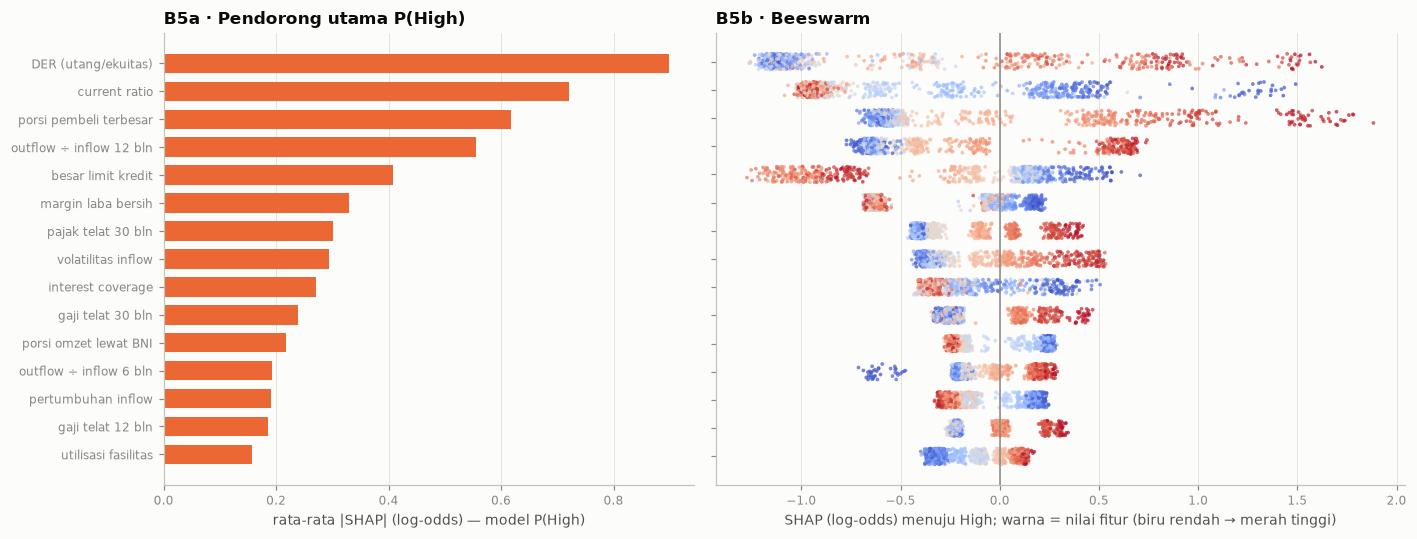

In [9]:
top = GLOBAL.head(15).index[::-1]
fig, ax = plt.subplots(1, 2, figsize=(13, 5), gridspec_kw={'width_ratios': [1, 1.3]})
ax[0].barh(range(len(top)), GLOBAL.loc[top, 'mean_abs_SHAP_High'], color=C['s2'], height=.7)
ax[0].set_yticks(range(len(top))); ax[0].set_yticklabels([nice(f) for f in top]); ax[0].set_xlabel('rata-rata |SHAP| (log-odds) — model P(High)')
ax[0].set_title('B5a · Pendorong utama P(High)'); ax[0].grid(axis='y', visible=False)
cmap = mpl.colormaps['coolwarm']; rng_b = np.random.default_rng(SEED)
for i, f in enumerate(top):
    v = SHAP_H[f].values; x = DEV[f].values if f in DEV else np.full(len(v), np.nan)
    c = pd.Series(x).rank(pct=True).fillna(.5).values
    ax[1].scatter(v, i + rng_b.uniform(-.28, .28, len(v)), c=cmap(c), s=6, alpha=.7, linewidths=0)
ax[1].axvline(0, color=C['muted'], lw=1); ax[1].set_yticks(range(len(top))); ax[1].set_yticklabels([])
ax[1].set_xlabel('SHAP (log-odds) menuju High; warna = nilai fitur (biru rendah → merah tinggi)'); ax[1].set_title('B5b · Beeswarm'); ax[1].grid(axis='y', visible=False)
fig.tight_layout(); save_fig(fig, 'B5_shap_global'); plt.show()

**Bentuk efek (dependence plot)** untuk 6 fitur teratas. Batasan monoton menjamin arahnya; grafik memperlihatkan **di mana** efeknya mulai kuat, sebagai bahan aturan praktis RM.

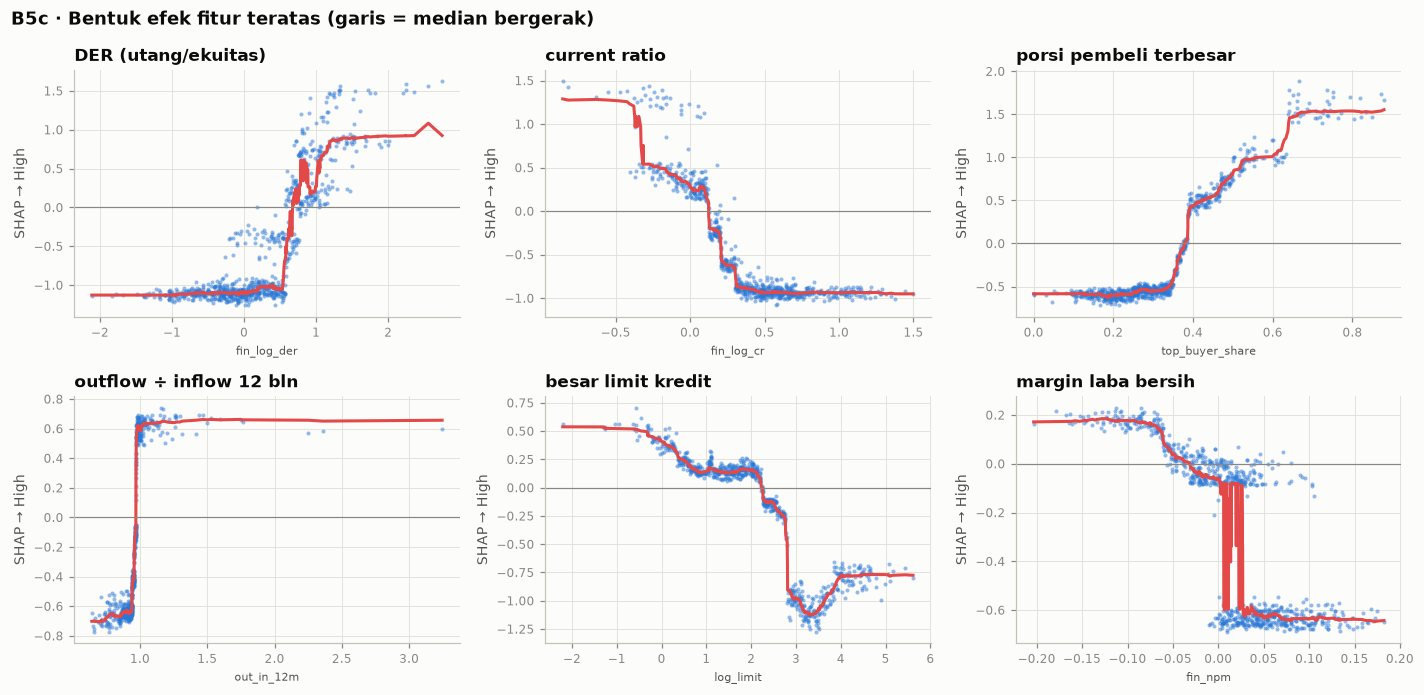

In [10]:
dep = [f for f in GLOBAL.index if f in DEV and DEV[f].nunique() > 5][:6]
fig, axes = plt.subplots(2, 3, figsize=(13, 6.4)); axes = axes.ravel()
for a_, f in zip(axes, dep):
    x = DEV[f].values; v = SHAP_H[f].values; ok_ = np.isfinite(x)
    a_.scatter(x[ok_], v[ok_], s=7, alpha=.5, color=C['s1'], linewidths=0)
    o = np.argsort(x[ok_]); a_.plot(x[ok_][o], pd.Series(v[ok_][o]).rolling(40, center=True, min_periods=10).median(), color=C['s8'], lw=2)
    a_.axhline(0, color=C['muted'], lw=.8); a_.set_title(nice(f)); a_.set_xlabel(f, fontsize=7.5); a_.set_ylabel('SHAP → High')
fig.suptitle('B5c · Bentuk efek fitur teratas (garis = median bergerak)', x=0.01, ha='left', fontweight='bold'); fig.tight_layout()
save_fig(fig, 'B5_shap_dependence'); plt.show()

**Interaksi, konsistensi dengan EDA, dan stabilitas antar-fold.**
- Interaksi: nilai interaksi TreeSHAP (XGBoost) model P(High), 5 pasangan terkuat (informasi).
- Konsistensi: setiap temuan utama EDA NB02 → peringkat fitur terkait di SHAP.
- Stabilitas: peringkat mean |SHAP| dari 5 model fold (di fold validasinya masing-masing) → korelasi Spearman antar-fold. Pendorong yang tidak stabil tidak dipakai untuk narasi.

In [11]:
rm = champ.model
if rm.kind == 'xgb' and HAS_XGB:
    est = rm.est_; cols = list(est.feature_names_in_); Xf = rm.transform_features(DEV)[cols].to_numpy(float)
    I = est.models_[1].get_booster().predict(xgb.DMatrix(Xf), pred_interactions=True)[:, :-1, :-1]
    M = np.abs(I).mean(0); np.fill_diagonal(M, 0); iu = np.triu_indices_from(M, 1)
    INTER = pd.DataFrame({'fitur_1': [nice(base_feat(cols[i])) for i in iu[0]], 'fitur_2': [nice(base_feat(cols[j])) for j in iu[1]], 'mean_abs_interaksi': 2 * M[iu]})
    INTER = INTER.sort_values('mean_abs_interaksi', ascending=False).head(5); INTER.to_csv(OUT / 'shap_interactions_top.csv', index=False); display(INTER.round(4))
else:
    print('interaksi TreeSHAP hanya untuk XGBoost — dilewati')

EDA_MAP = [('Timing bayar gaji/pajak (F2)', ['pay_late_30m', 'tax_late_30m', 'pay_late_12m', 'tax_late_12m', 'pay_late_6m', 'tax_late_6m', 'timing_delta', 'pay_split_12m']),
           ('Laporan tidak diserahkan — MNAR (D)', ['has_report', 'is_audited']),
           ('Konsentrasi pembeli (F3)', ['top_buyer_share']),
           ('Paparan anchor yang melemah (F4)', ['exp_shocked_anchor']),
           ('Rasio keuangan (+ relatif-peer, F1)', ['fin_log_der', 'fin_log_cr', 'fin_npm', 'fin_sicr']),
           ('Arus kas & wallet (F6)', ['out_in_6m', 'out_in_12m', 'capture_ratio', 'divergence', 'inflow_cv_sa'])]
EDA_TAB = pd.DataFrame([{'temuan EDA': t, 'fitur terkuat': nice(min([f for f in fl if f in GLOBAL.index], key=lambda f: GLOBAL.loc[f, 'peringkat_High'])),
                         'peringkat terbaik (dari %d)' % len(GLOBAL): int(GLOBAL.loc[[f for f in fl if f in GLOBAL.index], 'peringkat_High'].min()),
                         'porsi |SHAP| kelompok': GLOBAL.loc[[f for f in fl if f in GLOBAL.index], 'mean_abs_SHAP_High'].sum() / GLOBAL.mean_abs_SHAP_High.sum()}
                        for t, fl in EDA_MAP if any(f in GLOBAL.index for f in fl)])
EDA_TAB.to_csv(OUT / 'shap_vs_eda.csv', index=False); display(EDA_TAB.round(3))

fold_rank = {}
for k, ((tr, va), m) in enumerate(zip(FOLDS, FOLD_MODELS)):
    fold_rank[f'fold {k}'] = tree_contribs(m, DEV.iloc[va], 1).abs().mean()
FR = pd.DataFrame(fold_rank); STAB = FR.rank(ascending=False).corr(method='spearman')
top10 = GLOBAL.head(10).index; FR_top = FR.loc[top10].rank(ascending=False)
STAB_SUM = pd.DataFrame({'Spearman_rata2_antar_fold': [STAB.values[np.triu_indices(5, 1)].mean()],
                         'fitur_top10_selalu_top15': [int((FR.rank(ascending=False).loc[top10] <= 15).all(1).sum())]})
pd.concat([FR.rank(ascending=False).loc[top10].assign(fitur=[nice(f) for f in top10])]).to_csv(OUT / 'shap_stability.csv')
display(STAB_SUM.round(3))

,fitur_1,fitur_2,mean_abs_interaksi
501,DER (utang/ekuitas),besar limit kredit,0.0426
495,DER (utang/ekuitas),volatilitas inflow,0.0415
777,besar limit kredit,porsi pembeli terbesar,0.0394
649,gaji telat 30 bln,outflow ÷ inflow 6 bln,0.0364
140,interest coverage,outflow ÷ inflow 12 bln,0.0361


,temuan EDA,fitur terkuat,peringkat terbaik (dari 36),porsi |SHAP| kelompok
0,Timing bayar gaji/pajak (F2),pajak telat 30 bln,7,0.142
1,Laporan tidak diserahkan — MNAR (D),laporan keuangan diserahkan,34,0.000
2,Konsentrasi pembeli (F3),porsi pembeli terbesar,3,0.100
3,Paparan anchor yang melemah (F4),paparan ke anchor melemah,30,0.001
4,"Rasio keuangan (+ relatif-peer, F1)",DER (utang/ekuitas),1,0.359
5,Arus kas & wallet (F6),outflow ÷ inflow 12 bln,4,0.213


,Spearman_rata2_antar_fold,fitur_top10_selalu_top15
0,0.929,10


**Mengapa prospect banyak di-flag High?** Rata-rata SHAP (model `set_prospect`, P(High)) pada 600 prospect dibandingkan dengan 800 nasabah dev. Ini diagnosis pergeseran distribusi **tanpa** membuka GT prospect (bagian G).

In [12]:
pm = FINAL_MODELS['set_prospect']
SP_P, SP_D = tree_contribs(pm, PROS, 1), tree_contribs(pm, DEV, 1)
PVC = pd.DataFrame({'SHAP_prospect': SP_P.mean(), 'SHAP_nasabah': SP_D.mean()}); PVC['selisih'] = PVC.SHAP_prospect - PVC.SHAP_nasabah
PVC['nilai_prospect'] = [PROS[f].mean() if f in PROS else np.nan for f in PVC.index]; PVC['nilai_nasabah'] = [DEV[f].mean() if f in DEV else np.nan for f in PVC.index]
PVC = PVC.reindex(PVC.selisih.abs().sort_values(ascending=False).index); PVC.to_csv(OUT / 'shap_prospect_vs_client.csv')
display(PVC.head(8).rename(index=nice).round(3))
print(f'Selisih total log-odds High (prospect − nasabah): {PVC.selisih.sum():+.2f}; 3 penyumbang terbesar: {", ".join(nice(f) for f in PVC.index[:3])}')

,SHAP_prospect,SHAP_nasabah,selisih,nilai_prospect,nilai_nasabah
DER (utang/ekuitas),0.045,-0.817,0.863,0.243,0.203
current ratio,-0.138,-0.700,0.562,0.279,0.381
ukuran usaha,0.096,-0.253,0.349,0.383,0.981
margin laba bersih,-0.414,-0.635,0.221,0.005,0.012
interest coverage,-0.092,-0.215,0.123,0.795,0.869
porsi pembeli terbesar,-0.081,-0.143,0.062,0.345,0.331
industri aktivitas kesehatan,-0.019,-0.052,0.033,0.063,0.088
laporan diaudit,0.011,-0.013,0.024,0.278,0.581


Selisih total log-odds High (prospect − nasabah): +2.22; 3 penyumbang terbesar: DER (utang/ekuitas), current ratio, ukuran usaha


### B6. Aturan anomali dibekukan + pembanding Isolation Forest
- `models/06_final/anomaly_rules.json` = ambang NB04; `src/anomaly_rules.apply_rules` dipakai bersama notebook & dashboard.
- **Cek**: alarm dari modul harus identik dengan `outputs/scores/anomaly_alerts.csv` (NB04).
- **Isolation Forest** (Liu dkk., 2008) pada 17 fitur panel, di-fit pada nasabah non-test. Skornya tidak punya jenis kejadian, jadi dinilai dengan presisi top-k "jenis apa pun" dan recall per jenis (alarm apa pun). Anggaran alarm baru per bulan = champion.

In [13]:
PANEL = load_features(PROJECT_ROOT, 'anomaly'); ANOM_COLS = fs['anomaly']
ANOM_RULES = AR.load_rules(None); AR.save_rules(ANOM_RULES, FINAL / 'anomaly_rules.json')
A_CH = AR.apply_rules(PANEL, ANOM_RULES); A_SH = AR.apply_challenger(PANEL, ANOM_RULES)
ref_a = pd.read_csv(SCORES / 'anomaly_alerts.csv')
chk = ref_a[ref_a.champion_or_shadow == 'champion'].merge(A_CH, on=['company_id', 'ym', 'event_type'], how='outer', indicator=True)
same = (chk._merge == 'both').mean() == 1 and np.isclose(chk.score_x, chk.score_y.round(4)).all()
print(f'alarm champion modul vs NB04: {len(A_CH)} vs {(ref_a.champion_or_shadow == "champion").sum()} → {"✓ identik" if same else "⚠ berbeda — cek versi NB04"}')

P2 = PANEL[PANEL.ym >= ANOM_RULES['start_month']].reset_index(drop=True); MONTHS = sorted(P2.ym.unique()); P2['m'] = P2.ym.map({m: i for i, m in enumerate(MONTHS)})
TEST_FIRMS = set(df.company_id[df.split == 'test']); NONTEST_FIRMS = set(P2.company_id) - TEST_FIRMS
if RUN_ISOLATION_FOREST:
    imp_if = SimpleImputer(strategy='median').fit(P2.loc[P2.company_id.isin(NONTEST_FIRMS), ANOM_COLS])
    IF = IsolationForest(n_estimators=300, contamination='auto', random_state=SEED).fit(imp_if.transform(P2.loc[P2.company_id.isin(NONTEST_FIRMS), ANOM_COLS]))
    P2['if_score'] = -IF.score_samples(imp_if.transform(P2[ANOM_COLS]))
    budget = A_CH.groupby('ym').size()                                                    # anggaran alarm per bulan = champion
    P2['if_rank'] = P2.groupby('ym').if_score.rank(ascending=False, method='first')
    flag_if = P2.if_rank <= P2.ym.map(budget).fillna(0)
    A_IF = P2.loc[flag_if, ['company_id', 'ym', 'm']].assign(event_type='any', score=P2.loc[flag_if, 'if_score'].values, rule='Isolation Forest', source='Isolation Forest')
    A_IF = A_IF.sort_values(['company_id', 'm']); prev = A_IF.groupby('company_id').m.shift(1); A_IF['is_new'] = prev.isna() | (A_IF.m - prev > 1)
    print(f'Isolation Forest: {len(A_IF)} alarm (anggaran sama dengan champion)')
ANOM_RULES_HASH = hashlib.sha256((FINAL / 'anomaly_rules.json').read_bytes()).hexdigest()

alarm champion modul vs NB04: 6587 vs 6587 → ✓ identik
Isolation Forest: 6587 alarm (anggaran sama dengan champion)


### B7. Simpan model final + uji muat ulang gaya dashboard
`models/06_final/`: `champion__<set>.joblib` (terkalibrasi), `domain_model.joblib`, `anomaly_rules.json`, `manifest.json`. Sel uji memuat ulang model **persis seperti Streamlit** (path + `sys.path` ke `src/`) dan memastikan keputusannya sama.

In [14]:
for sn, m in FINAL_MODELS.items(): joblib.dump(m, FINAL / f'champion__{sn}.joblib', compress=3)
joblib.dump(PROSPECT_NOIW, FINAL / 'challenger__set_prospect_noIW.joblib', compress=3)
joblib.dump(DOMAIN_MODEL, FINAL / 'domain_model.joblib', compress=3)
MANIFEST = {
    'champion': 'M3_t XGBoost ordinal monoton (tuning NB05)', 'model_version': 'XGB-v2-NB06', 'basis': BASE, 'hiperparameter': PARAMS,
    'penyeimbangan': WEIGHTING, 'kalibrasi': CAL_METHOD, 'feature_sets': FEATURE_SETS, 'populasi_ke_set': POP_SET,
    'dilatih_pada': 'train + valid (800 nasabah kredit); test tidak ikut', 'risk_order': RISK_ORDER, 'matriks_biaya': COST.tolist(),
    'target_recall_High': TARGET_RECALL, 'alpha_conformal': ALPHA,
    'aturan_keputusan': {sn: {'ambang_P_High': r['t_high'], 'q_per_kelas': dict(zip(RISK_ORDER, map(float, r['q_kelas'])))} for sn, r in RULES.items()},
    'prospect': {'iw_power': IW_POWER, 'iw_clip': IW_CLIP, 'ratio': RATIO, 'weighted_conformal_scores': RULES['set_prospect']['scores_cal'].round(6).tolist(),
                 'weighted_conformal_w': W_DEV.round(6).tolist()},
    'keputusan_Low_vs_Medium': 'biaya harapan terkecil (P @ matriks_biaya)',
    'versi_pustaka': {'python': sys.version.split()[0], 'scikit-learn': sklearn.__version__, 'numpy': np.__version__, 'pandas': pd.__version__,
                      'xgboost': xgb.__version__ if HAS_XGB else None},
}
(FINAL / 'manifest.json').write_text(json.dumps(MANIFEST, ensure_ascii=False, indent=1, default=float), encoding='utf-8')

# uji muat ulang gaya dashboard
_m = joblib.load(FINAL / 'champion__set_core.joblib'); _man = json.loads((FINAL / 'manifest.json').read_text(encoding='utf-8'))
_P = _m.predict_proba(DEV.head(50)); _rule = _man['aturan_keputusan']['set_core']
assert np.allclose(_P, champ.predict_proba(DEV.head(50)))
assert (decide(_P, _rule['ambang_P_High']) == decide(champ.predict_proba(DEV.head(50)), RULES['set_core']['t_high'])).all()
print(f'model final tersimpan di {FINAL.relative_to(PROJECT_ROOT)} ✓ muat ulang gaya dashboard identik')

model final tersimpan di models\06_final ✓ muat ulang gaya dashboard identik


## C. Kunci evaluasi (pra-registrasi)
Sebelum label test dan ground truth dibaca, dicatat: waktu, hash SHA-256 semua file model & aturan, konfigurasi, dan daftar model yang akan dinilai. Fungsi `verify_lock()` dipanggil di awal setiap bagian penilaian; bila ada file yang berubah setelah kunci, notebook berhenti.

In [15]:
def sha(p): return hashlib.sha256(Path(p).read_bytes()).hexdigest()
LOCK_FILES = sorted([*FINAL.glob('*.joblib'), FINAL / 'manifest.json', FINAL / 'anomaly_rules.json', M05 / 'champion__set_core.joblib', M05 / 'manifest.json'])
LOCK = {'waktu_kunci': datetime.now().isoformat(timespec='seconds'),
        'hash': {str(p.relative_to(PROJECT_ROOT)): sha(p) for p in LOCK_FILES},
        'model_dinilai_di_test': {'champion': MANIFEST['champion'], 'pembanding': f'{COMP_NAME} (models/05_optimization)'},
        'konfigurasi': {'target_recall_High': TARGET_RECALL, 'alpha': ALPHA, 'penyeimbangan': WEIGHTING, 'kalibrasi': CAL_METHOD, 'K_TOP': K_TOP,
                        'asumsi_bisnis': ASSUMPTIONS, 'matriks_biaya': COST.tolist()},
        'aturan_keputusan': MANIFEST['aturan_keputusan'], 'OOF_champion': OOF_SUMMARY}
(OUT / 'evaluation_lock.json').write_text(json.dumps(LOCK, ensure_ascii=False, indent=1, default=float), encoding='utf-8')
def verify_lock():
    bad = [f for f, h in LOCK['hash'].items() if sha(PROJECT_ROOT / f) != h]
    assert not bad, f'File berubah setelah kunci evaluasi: {bad}'
verify_lock()
print(f'🔒 evaluasi dikunci {LOCK["waktu_kunci"]} — {len(LOCK["hash"])} file di-hash → {(OUT / "evaluation_lock.json").relative_to(PROJECT_ROOT)}')

🔒 evaluasi dikunci 2026-10-11T16:27:02 — 9 file di-hash → outputs\06_evaluation\evaluation_lock.json


## D. Kinerja risiko di test (200 nasabah kredit, label rating)
Label test dan ground truth **baru dibaca di sini**. Rentang 95% dari bootstrap 2.000× atas nasabah test. Test hanya memuat ±28 kasus High, jadi satu nasabah ≈ 3,6 poin recall; selisih kecil harus dibaca bersama rentangnya.

In [16]:
verify_lock()
TRUTH_ALL = load_features(PROJECT_ROOT, 'risk')[['company_id', 'split', 'risk_class']]
TEST = df[df.split == 'test'].reset_index(drop=True)
y_test = TEST.company_id.map(TRUTH_ALL.set_index('company_id').risk_class).map(Y_MAP).astype(int).values
GT_CLIENT = pd.read_csv(EVAL / 'client_true_risk_and_label_flip.csv').set_index('company_id')
GT_PROS = pd.read_csv(EVAL / 'prospect_true_risk.csv').set_index('company_id')
EV_ANOM = pd.read_csv(EVAL / 'anomaly_events_monthly.csv')
print(f'test: {len(TEST)} nasabah · {pd.Series(y_test).map(dict(enumerate(RISK_ORDER))).value_counts().reindex(RISK_ORDER).to_dict()}')

Q_test = champ.predict_proba(TEST); pred_test, S_test, auto_test = decision_block(Q_test, 'set_core')
Qc_test = COMP_MODEL.predict_proba(TEST); predc_test = decide(Qc_test, COMP_RULE['t_high'])
Sc_test = sets_classcond(Qc_test, COMP_RULE['q_kelas']); autoc_test = (Sc_test.sum(1) == 1) & Sc_test[np.arange(len(TEST)), predc_test]
BOOT_T = np.random.default_rng(SEED + 1).integers(0, len(TEST), size=(N_BOOT, len(TEST)))

def metric_row(y, P, pred, auto=None):
    return {'macro_F1_keputusan': macro_f1(y, pred), 'recall_High': recall_high(y, pred), 'presisi_High': ((pred == 2) & (y == 2)).sum() / max((pred == 2).sum(), 1),
            'flag_High': int((pred == 2).sum()), 'biaya': int(row_cost(y, pred).sum()), 'AUC_High': roc_auc_score(y == 2, P[:, 2]),
            'Brier': brier(y, P), 'ECE_High': ece(y, P, n_bins=5, cls=2), 'macro_F1_argmax': macro_f1(y, P.argmax(1)),
            **({'pct_otomatis': 100 * auto.mean()} if auto is not None else {})}
def boot_ci(fn, *arrs):
    v = np.array([fn(*[a[b] for a in arrs]) for b in BOOT_T]); return np.percentile(v, [2.5, 97.5])

TM = pd.DataFrame({'champion XGB': metric_row(y_test, Q_test, pred_test, auto_test), f'pembanding {COMP_NAME}': metric_row(y_test, Qc_test, predc_test, autoc_test)}).T
for met, fn in [('macro_F1_keputusan', lambda y, p: macro_f1(y, p)), ('recall_High', lambda y, p: recall_high(y, p))]:
    TM.loc['champion XGB', f'{met}_lo95'], TM.loc['champion XGB', f'{met}_hi95'] = boot_ci(fn, y_test, pred_test)
    TM.loc[f'pembanding {COMP_NAME}', f'{met}_lo95'], TM.loc[f'pembanding {COMP_NAME}', f'{met}_hi95'] = boot_ci(fn, y_test, predc_test)
d_f1 = np.array([macro_f1(y_test[b], pred_test[b]) - macro_f1(y_test[b], predc_test[b]) for b in BOOT_T])
d_cost = row_cost(y_test, pred_test) - row_cost(y_test, predc_test); d_cost_b = d_cost[BOOT_T].sum(1)
right_c, right_l = pred_test == y_test, predc_test == y_test
mcn = stats.binomtest(int((right_c & ~right_l).sum()), int((right_c != right_l).sum()), 0.5) if (right_c != right_l).any() else None
DIFF = pd.DataFrame([{'ΔmacroF1 (champion − pembanding)': d_f1.mean(), 'lo95': np.percentile(d_f1, 2.5), 'hi95': np.percentile(d_f1, 97.5), 'p (Δ ≤ 0)': (d_f1 <= 0).mean(),
                      'Δbiaya': int(d_cost.sum()), 'Δbiaya_lo95': np.percentile(d_cost_b, 2.5), 'Δbiaya_hi95': np.percentile(d_cost_b, 97.5),
                      'McNemar: benar hanya champion': int((right_c & ~right_l).sum()), 'benar hanya pembanding': int((~right_c & right_l).sum()),
                      'p McNemar (eksak)': mcn.pvalue if mcn else np.nan}])
TM.to_csv(OUT / 'test_metrics.csv'); DIFF.to_csv(OUT / 'test_champion_vs_comparator.csv', index=False)
display(TM.round(3)); display(DIFF.round(3))

test: 200 nasabah · {'Low': 123, 'Medium': 49, 'High': 28}


,macro_F1_keputusan,recall_High,presisi_High,flag_High,biaya,AUC_High,Brier,ECE_High,macro_F1_argmax,pct_otomatis,macro_F1_keputusan_lo95,macro_F1_keputusan_hi95,recall_High_lo95,recall_High_hi95
champion XGB,0.633,0.893,0.472,53.0,93.0,0.932,0.339,0.018,0.642,44.5,0.558,0.701,0.762,1.000
pembanding M1_v0,0.574,0.821,0.411,56.0,108.0,0.913,0.354,0.037,0.664,50.0,0.500,0.643,0.667,0.955


,ΔmacroF1 (champion − pembanding),lo95,hi95,p (Δ ≤ 0),Δbiaya,Δbiaya_lo95,Δbiaya_hi95,McNemar: benar hanya champion,benar hanya pembanding,p McNemar (eksak)
0,0.058,-0.01,0.127,0.044,-15,-44.0,14.025,23,12,0.09


### D2. OOF (dev) vs test — tanda overfitting?
Penurunan macro-F1 keputusan > 0,05 dari OOF ke test ditandai. Dengan 200 nasabah, selisih ±0,05 masih wajar karena acak.

In [17]:
rows = []
for nm, Qo, ro, Qt, pt, at in [('champion XGB', Q_oof, RULES['set_core'], Q_test, pred_test, auto_test),
                               (f'pembanding {COMP_NAME}', Q_comp_oof, COMP_RULE, Qc_test, predc_test, autoc_test)]:
    if Qo is None: continue
    po = decide(Qo, ro['t_high']); So = sets_classcond(Qo, ro['q_kelas']); ao = (So.sum(1) == 1) & So[np.arange(len(Qo)), po]
    o, t = metric_row(y_dev, Qo, po, ao), metric_row(y_test, Qt, pt, at)
    for k in ['macro_F1_keputusan', 'recall_High', 'presisi_High', 'AUC_High', 'Brier', 'pct_otomatis']:
        rows.append({'model': nm, 'metrik': k, 'OOF_dev': o[k], 'test': t[k], 'selisih': t[k] - o[k]})
OVT = pd.DataFrame(rows); OVT['tanda'] = np.where((OVT.metrik == 'macro_F1_keputusan') & (OVT.selisih < -0.05), '⚠ turun > 0,05', '')
OVT.to_csv(OUT / 'oof_vs_test.csv', index=False); display(OVT.pivot(index='metrik', columns='model', values=['OOF_dev', 'test']).round(3))

OOF_dev                          test                 
model              champion XGB pembanding M1_v0 champion XGB pembanding M1_v0
metrik                                                                        
AUC_High                  0.953            0.944        0.932            0.913
Brier                     0.305            0.316        0.339            0.354
macro_F1_keputusan        0.653            0.612        0.633            0.574
pct_otomatis             51.875           50.000       44.500           50.000
presisi_High              0.524            0.481        0.472            0.411
recall_High               0.908            0.908        0.893            0.821

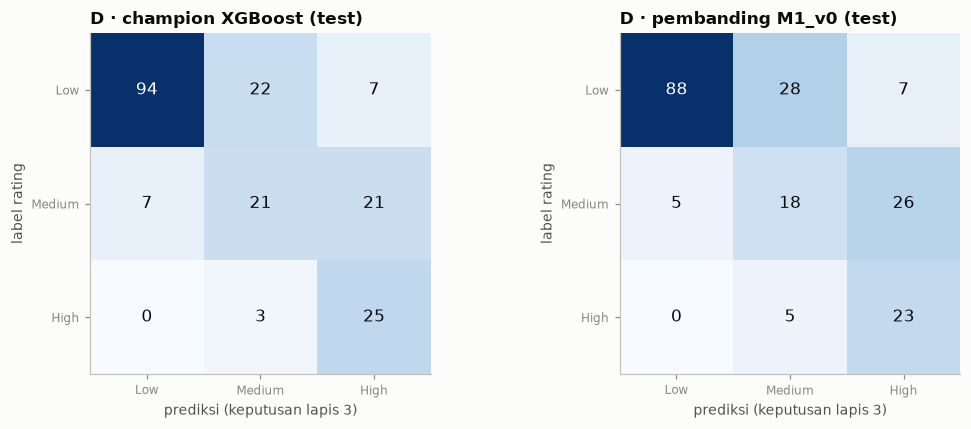

,segmen,n,n_High,macro_F1_champion,macro_F1_pembanding,recall_High_champion
0,Kecil,65,10,0.728,0.728,0.900
1,Menengah,99,14,0.591,0.515,0.929
2,Besar,36,4,0.577,0.472,0.750


n per segmen kecil → deskriptif saja.


In [18]:
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
for a_, (nm, pr) in zip(ax, [('champion XGBoost', pred_test), (f'pembanding {COMP_NAME}', predc_test)]):
    cm = confusion_matrix(y_test, pr, labels=[0, 1, 2]); a_.imshow(cm, cmap='Blues')
    for i in range(3):
        for j in range(3): a_.text(j, i, cm[i, j], ha='center', va='center', color='white' if cm[i, j] > cm.max() / 2 else C['ink'], fontsize=11)
    a_.set_xticks(range(3)); a_.set_xticklabels(RISK_ORDER); a_.set_yticks(range(3)); a_.set_yticklabels(RISK_ORDER); a_.grid(False)
    a_.set_xlabel('prediksi (keputusan lapis 3)'); a_.set_ylabel('label rating'); a_.set_title(f'D · {nm} (test)')
fig.tight_layout(); save_fig(fig, 'D_confusion_test'); plt.show()
SEG_T = TEST.size_class_reference.values
SEGTAB = pd.DataFrame([{'segmen': s, 'n': int((SEG_T == s).sum()), 'n_High': int((y_test[SEG_T == s] == 2).sum()),
                        'macro_F1_champion': macro_f1(y_test[SEG_T == s], pred_test[SEG_T == s]), 'macro_F1_pembanding': macro_f1(y_test[SEG_T == s], predc_test[SEG_T == s]),
                        'recall_High_champion': recall_high(y_test[SEG_T == s], pred_test[SEG_T == s])} for s in ['Kecil', 'Menengah', 'Besar']])
SEGTAB.to_csv(OUT / 'test_by_segment.csv', index=False); display(SEGTAB.round(3)); print('n per segmen kecil → deskriptif saja.')

## E. Apakah jaminan berlaku di data baru? (kalibrasi & conformal di test)
Cakupan = % nasabah test yang kelas sebenarnya (label rating) ada di himpunan conformal. Target ≥ 90%; rentang 95% Clopper–Pearson.

,kelompok,n,cakupan,lo95,hi95
0,semua,200,0.915,0.867,0.950
1,kelas Low,123,0.902,0.836,0.949
2,kelas Medium,49,0.939,0.831,0.987
3,kelas High,28,0.929,0.765,0.991
4,segmen Kecil,65,0.954,0.871,0.990
5,segmen Menengah,99,0.899,0.822,0.950
6,segmen Besar,36,0.889,0.739,0.969


,% otomatis,macro_F1_otomatis,akurasi_otomatis,High_lolos_sebagai_otomatis,macro_F1_review
model,,,,,
champion XGB,44.5,0.825,0.888,1,0.539
pembanding M1_v0,50.0,0.644,0.820,5,0.469


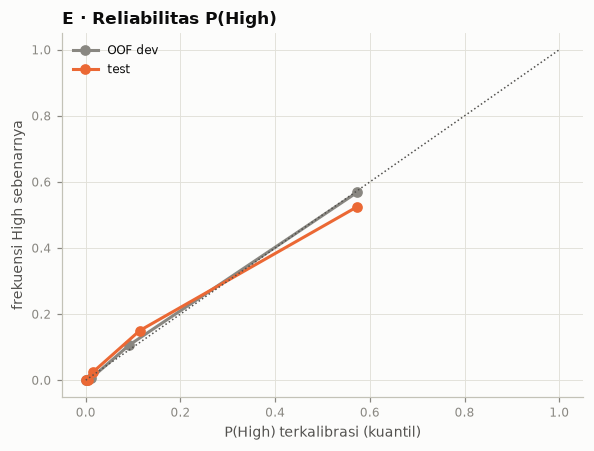

In [19]:
verify_lock()
def cov_row(S, y, mask, name):
    k = int(S[mask][np.arange(mask.sum()), y[mask]].sum()); n = int(mask.sum())
    ci = stats.binomtest(k, n).proportion_ci(0.95) if n else None
    return {'kelompok': name, 'n': n, 'cakupan': k / n if n else np.nan, 'lo95': ci.low if ci else np.nan, 'hi95': ci.high if ci else np.nan}
rows = [cov_row(S_test, y_test, np.ones(len(TEST), bool), 'semua')] + [cov_row(S_test, y_test, y_test == k, f'kelas {RISK_ORDER[k]}') for k in range(3)] + \
       [cov_row(S_test, y_test, SEG_T == s, f'segmen {s}') for s in ['Kecil', 'Menengah', 'Besar']]
COVT = pd.DataFrame(rows); COVT.to_csv(OUT / 'conformal_test.csv', index=False); display(COVT.round(3))
AUTO_T = pd.DataFrame([{'model': 'champion XGB', '% otomatis': 100 * auto_test.mean(), 'macro_F1_otomatis': macro_f1(y_test[auto_test], pred_test[auto_test]),
                        'akurasi_otomatis': (pred_test[auto_test] == y_test[auto_test]).mean(), 'High_lolos_sebagai_otomatis': int(((y_test == 2) & auto_test & (pred_test != 2)).sum()),
                        'macro_F1_review': macro_f1(y_test[~auto_test], pred_test[~auto_test])},
                       {'model': f'pembanding {COMP_NAME}', '% otomatis': 100 * autoc_test.mean(), 'macro_F1_otomatis': macro_f1(y_test[autoc_test], predc_test[autoc_test]),
                        'akurasi_otomatis': (predc_test[autoc_test] == y_test[autoc_test]).mean(), 'High_lolos_sebagai_otomatis': int(((y_test == 2) & autoc_test & (predc_test != 2)).sum()),
                        'macro_F1_review': macro_f1(y_test[~autoc_test], predc_test[~autoc_test])}]).set_index('model')
AUTO_T.to_csv(OUT / 'automation_test.csv'); display(AUTO_T.round(3))

fig, ax = plt.subplots(figsize=(5.5, 4.2))
for Q_, y_, nm, col in [(Q_oof, y_dev, 'OOF dev', C['muted']), (Q_test, y_test, 'test', C['s2'])]:
    edges = np.quantile(Q_[:, 2], np.linspace(0, 1, 6)); b = np.clip(np.digitize(Q_[:, 2], edges[1:-1]), 0, 4)
    ax.plot([Q_[b == i, 2].mean() for i in range(5)], [(y_[b == i] == 2).mean() for i in range(5)], '-o', color=col, label=nm)
ax.plot([0, 1], [0, 1], ':', color=C['ink2'], lw=1); ax.set_xlabel('P(High) terkalibrasi (kuantil)'); ax.set_ylabel('frekuensi High sebenarnya')
ax.set_title('E · Reliabilitas P(High)'); ax.legend(); fig.tight_layout(); save_fig(fig, 'E_reliability_test'); plt.show()

## F. Label berisik: label rating vs kelas sebenarnya
`client_true_risk_and_label_flip`: sebagian label rating diketahui salah (dipindah ke kelas tetangga). Pertanyaan:
1. Bagaimana kinerja terhadap **kelas sebenarnya**?
2. Pada label yang salah, seberapa sering model memprediksi **kelas sebenarnya**, bukan label rating? Dihitung di 1.000 nasabah (OOF dev + test) supaya sampelnya cukup.

In [20]:
verify_lock()
true_test = GT_CLIENT.true_risk_class.reindex(TEST.company_id).map(Y_MAP).values.astype(int)
LN = pd.DataFrame({'label rating': metric_row(y_test, Q_test, pred_test), 'kelas sebenarnya': metric_row(true_test, Q_test, pred_test)}).T
LN.to_csv(OUT / 'label_noise_test.csv'); display(LN[['macro_F1_keputusan', 'recall_High', 'presisi_High', 'AUC_High', 'Brier']].round(3))
ids_all = np.r_[DEV.company_id.values, TEST.company_id.values]; pred_all = np.r_[pred_oof, pred_test]
lab_all = np.r_[y_dev, y_test]; true_all = GT_CLIENT.true_risk_class.reindex(ids_all).map(Y_MAP).values.astype(int)
flip = GT_CLIENT.label_flipped.reindex(ids_all).values.astype(bool)
FLIP = pd.DataFrame([{'kelompok': 'label benar', 'n': int((~flip).sum()), 'prediksi = label': (pred_all[~flip] == lab_all[~flip]).mean()},
                     {'kelompok': 'label salah (flip)', 'n': int(flip.sum()), 'prediksi = label': (pred_all[flip] == lab_all[flip]).mean(),
                      'prediksi = kelas sebenarnya': (pred_all[flip] == true_all[flip]).mean()}])
FLIP.to_csv(OUT / 'label_noise_flip.csv', index=False); display(FLIP.round(3))
print(f'Pada {int(flip.sum())} label yang salah, model menebak kelas SEBENARNYA {(pred_all[flip] == true_all[flip]).mean():.0%} '
      f'vs mengikuti label salah {(pred_all[flip] == lab_all[flip]).mean():.0%}.')

,macro_F1_keputusan,recall_High,presisi_High,AUC_High,Brier
label rating,0.633,0.893,0.472,0.932,0.339
kelas sebenarnya,0.660,0.963,0.491,0.954,0.316


,kelompok,n,prediksi = label,prediksi = kelas sebenarnya
0,label benar,956,0.723,NaN
1,label salah (flip),44,0.295,0.682


Pada 44 label yang salah, model menebak kelas SEBENARNYA 68% vs mengikuti label salah 30%.


## G. Prospect & nasabah non-kredit terhadap ground truth
- **Prospect (600)**: versi dengan importance weighting (champion) vs tanpa bobot; cakupan weighted conformal.
- **Non-kredit (400)**: ground truth tidak tersedia di `eval_targets/`; bila ada `gt_*` di `data/raw/` yang memuat nasabah non-kredit, dipakai; bila tidak, hanya distribusi prediksi.

In [21]:
verify_lock()
y_pros = GT_PROS.true_risk_class.reindex(PROS.company_id).map(Y_MAP).values.astype(int)
rows = []
for nm, mdl, rule_name in [('IW (champion)', FINAL_MODELS['set_prospect'], 'set_prospect'), ('tanpa bobot', PROSPECT_NOIW, 'set_prospect_noIW')]:
    Pp = mdl.predict_proba(PROS); pp = decide(Pp, RULES[rule_name]['t_high'])
    if rule_name == 'set_prospect':
        Sp = sets_from_q(Pp, weighted_conformal_q(RULES['set_prospect']['scores_cal'], W_DEV, iw(DOMAIN_MODEL.predict_proba(PROS)[:, 1]), ALPHA))
    else:
        Sp = sets_classcond(Pp, RULES[rule_name]['q_kelas'])
    rows.append({'versi': nm, **metric_row(y_pros, Pp, pp, (Sp.sum(1) == 1) & Sp[np.arange(len(Pp)), pp]), '% flag High': 100 * (pp == 2).mean(),
                 'cakupan_conformal': Sp[np.arange(len(Pp)), y_pros].mean(), 'cakupan_High': Sp[y_pros == 2][:, 2].mean()})
PRO = pd.DataFrame(rows).set_index('versi'); PRO['% High sebenarnya'] = 100 * (y_pros == 2).mean()
PRO.to_csv(OUT / 'prospect_eval.csv'); display(PRO[['macro_F1_keputusan', 'recall_High', 'presisi_High', '% flag High', '% High sebenarnya', 'AUC_High', 'Brier',
                                                    'cakupan_conformal', 'cakupan_High', 'pct_otomatis']].round(3))
NONC = POP[POP.feature_set == 'set_noncredit'].reset_index(drop=True)
gt_nc = None
for f in sorted(RAW.glob('gt_*.csv')) if RAW.exists() else []:
    g = pd.read_csv(f)
    if 'company_id' in g and g.company_id.isin(NONC.company_id).any() and any(c in g for c in ('true_risk_class', 'risk_class')):
        gt_nc = g.set_index('company_id'); print(f'GT non-kredit ditemukan: {f.name}'); break
Pn = FINAL_MODELS['set_noncredit'].predict_proba(NONC); pn = decide(Pn, RULES['set_noncredit']['t_high'])
if gt_nc is not None:
    yn = gt_nc[[c for c in ('true_risk_class', 'risk_class') if c in gt_nc][0]].reindex(NONC.company_id).map(Y_MAP)
    ok_n = yn.notna().values; NCR = pd.Series(metric_row(yn[ok_n].astype(int).values, Pn[ok_n], pn[ok_n]), name='non-kredit vs GT')
    display(NCR.round(3).to_frame().T)
else:
    print('GT non-kredit tidak tersedia → distribusi prediksi saja (batasan dicatat di kartu model):')
    display(pd.Series(pn).map(dict(enumerate(RISK_ORDER))).value_counts(normalize=True).reindex(RISK_ORDER).round(3).to_frame('porsi prediksi').T)

,macro_F1_keputusan,recall_High,presisi_High,% flag High,% High sebenarnya,AUC_High,Brier,cakupan_conformal,cakupan_High,pct_otomatis
versi,,,,,,,,,,
IW (champion),0.566,0.960,0.517,53.5,28.833,0.866,0.480,0.860,0.913,38.0
tanpa bobot,0.567,0.948,0.521,52.5,28.833,0.880,0.472,0.828,0.948,39.0


GT non-kredit ditemukan: gt_risk.csv


,macro_F1_keputusan,recall_High,presisi_High,flag_High,biaya,AUC_High,Brier,ECE_High,macro_F1_argmax
non-kredit vs GT,0.574,0.889,0.429,112.0,211.0,0.95,0.299,0.036,0.718


## H. Anomali di perusahaan test
Aturan & ambang **sama dengan NB04** (dibekukan di B6). k diskalakan ke jumlah nasabah: 30 untuk ±1.200 non-test → ±5 untuk 200 nasabah test. Angka non-test dihitung ulang dengan kode yang sama sebagai acuan stabilitas.

In [22]:
verify_lock()
K_TEST = max(1, round(K_TOP * len(TEST_FIRMS & set(P2.company_id)) / len(NONTEST_FIRMS)))
RES_A = {}
for nm, A_ in [('champion aturan', A_CH), ('challenger skor gabungan', A_SH)]:
    for grp, firms, k in [('non-test', NONTEST_FIRMS, K_TOP), ('test', TEST_FIRMS, K_TEST)]:
        R_, O_, _ = AR.evaluate_alerts(A_, EV_ANOM, firms, MONTHS, k_top=k); RES_A[(nm, grp)] = (R_, O_)
ANOM_OV = pd.DataFrame({f'{nm} · {grp}': O_ for (nm, grp), (R_, O_) in RES_A.items()}).T
ANOM_BY = pd.concat([R_.assign(model=nm, kelompok=grp) for (nm, grp), (R_, O_) in RES_A.items()])
ANOM_OV.to_csv(OUT / 'anomaly_overall.csv'); ANOM_BY.to_csv(OUT / 'anomaly_by_type.csv', index=False)
display(ANOM_OV[['k', 'presisi_top_k', 'presisi_top_k_jenis_apa_pun', 'alarm_palsu_per_100_nasabah_per_bulan', 'lead_median_distress', 'pct_distress_lead_ge_1bln']].round(3))
display(ANOM_BY[ANOM_BY.model == 'champion aturan'].pivot(index='jenis', columns='kelompok', values=['presisi_alarm_baru', 'recall_kejadian', 'recall_dini']).round(3))

,k,presisi_top_k,presisi_top_k_jenis_apa_pun,alarm_palsu_per_100_nasabah_per_bulan,lead_median_distress,pct_distress_lead_ge_1bln
champion aturan · non-test,30.0,0.304,0.475,5.750,1.0,0.738
champion aturan · test,5.0,0.342,0.558,5.750,0.0,0.375
challenger skor gabungan · non-test,30.0,0.198,0.315,4.194,1.0,0.551
challenger skor gabungan · test,5.0,0.210,0.361,4.125,-0.5,0.333


presisi_alarm_baru        recall_kejadian        recall_dini       
kelompok                 non-test   test        non-test   test    non-test   test
jenis                                                                             
buyer_exit                  0.088  0.077           0.963  1.000       0.963  1.000
contagion                   0.300  0.429           0.430  0.389       0.409  0.389
distress                    0.081  0.074           1.000  1.000       1.000  1.000
expansion                   0.261  0.323           0.453  0.457       0.265  0.152
spike                       0.262  0.391           0.626  0.750       0.626  0.750
wallet_erosion              0.279  0.182           0.756  0.778       0.013  0.111

### H2. Isolation Forest vs aturan (jenis apa pun)
Isolation Forest tidak memberi jenis kejadian, jadi dibandingkan pada ukuran yang adil untuk keduanya: presisi top-k "kejadian jenis apa pun", recall kejadian oleh alarm apa pun, dan alarm palsu.

In [23]:
def any_type_eval(A_, firms, k):
    mi = {m: i for i, m in enumerate(sorted(set(EV_ANOM.ym) | set(MONTHS)))}; off = mi[MONTHS[0]]
    E = EV_ANOM[EV_ANOM.company_id.isin(firms)].copy(); E['m'] = E.ym.map(mi) - off; E['type'] = E.event_type.replace({'early_warning': 'distress'})
    ACT = set(zip(E.company_id, E.m)); ON = E[(E.is_onset == 1) & (E.event_type != 'early_warning')]; END = E.groupby(['company_id', 'type']).m.max().to_dict()
    A_ = A_[A_.company_id.isin(firms)].copy(); A_['tp_any'] = [any((c, m + d) in ACT for d in (-1, 0, 1)) for c, m in zip(A_.company_id, A_.m)]
    new = A_[A_.is_new]; top = new.sort_values('score', ascending=False).groupby('ym').head(k); ms = A_.groupby('company_id').m.apply(list).to_dict()
    rec = {t: np.mean([any(m0 - (3 if t == 'distress' else 1) <= m <= END[(c, t)] + 1 for m in ms.get(c, [])) for c, m0 in zip(g.company_id, g.m)])
           for t, g in ON.groupby('type')}
    return {'presisi_top_k_jenis_apa_pun': top.tp_any.mean(), 'alarm_palsu_per_100_per_bulan': 100 * (~new.tp_any).sum() / len(firms) / len(MONTHS),
            **{f'recall_{t}': v for t, v in rec.items()}}
if RUN_ISOLATION_FOREST:
    IFC = pd.DataFrame({f'{nm} · {grp}': any_type_eval(A_, firms, k) for nm, A_ in [('aturan (champion)', A_CH), ('Isolation Forest', A_IF)]
                        for grp, firms, k in [('non-test', NONTEST_FIRMS, K_TOP), ('test', TEST_FIRMS, K_TEST)]}).T
    IFC.to_csv(OUT / 'anomaly_isolation_forest_vs_rules.csv'); display(IFC.round(3))

,presisi_top_k_jenis_apa_pun,alarm_palsu_per_100_per_bulan,recall_buyer_exit,recall_contagion,recall_distress,recall_expansion,recall_spike,recall_wallet_erosion
aturan (champion) · non-test,0.475,5.750,0.981,0.753,1.0,0.746,0.861,0.897
aturan (champion) · test,0.558,5.750,1.000,0.833,1.0,0.717,0.958,0.889
Isolation Forest · non-test,0.404,4.531,0.926,0.817,1.0,0.652,0.896,0.885
Isolation Forest · test,0.525,4.417,1.000,0.833,1.0,0.674,1.000,0.889


## I. Dampak bisnis (Rp) — nasabah kredit test, horizon 12 bulan
Per nasabah: **EAD** = limit fasilitas (Rp miliar, dari `log_limit`). PD per **kelas sebenarnya** (GT), LGD, dan efektivitas mitigasi dari konfigurasi.
- **Kerugian dicegah** = Σ nasabah High sebenarnya yang di-flag × EAD × PD_High × LGD × mitigasi.
- **Biaya alarm** = jumlah flag High × biaya review.
- **Nilai bersih** = kerugian dicegah − biaya alarm. Skenario: tanpa sistem (0), pembanding, champion.

Semua angka adalah **ilustrasi berbasis asumsi** pada data sintetis; yang bermakna adalah **selisih antar-skenario** dan sensitivitasnya, bukan nilai mutlak.

In [24]:
verify_lock()
EAD = np.exp(TEST.log_limit.values)                                         # Rp miliar
true_high = true_test == 2
def impact(pred, a=ASSUMPTIONS, idx=None):
    idx = np.arange(len(pred)) if idx is None else idx; f = pred[idx] == 2; th = true_high[idx]
    prevented = (EAD[idx] * th * f).sum() * a['PD_High'] * a['LGD'] * a['mitigasi']
    missed = (EAD[idx] * th * ~f).sum() * a['PD_High'] * a['LGD']
    review = f.sum() * a['biaya_review_Rp_juta'] / 1000
    return {'kerugian_dicegah_Rp_mn': prevented * 1000, 'biaya_review_Rp_mn': review * 1000, 'nilai_bersih_Rp_mn': (prevented - review) * 1000,
            'kerugian_High_tak_terdeteksi_Rp_mn': missed * 1000, 'n_flag': int(f.sum()), 'High_sebenarnya_tertangkap': int((th & f).sum()), 'High_sebenarnya': int(th.sum())}
SCEN = {'tanpa sistem': np.zeros(len(TEST), int), f'pembanding {COMP_NAME}': predc_test, 'champion XGB': pred_test}
BI = pd.DataFrame({k: impact(p) for k, p in SCEN.items()}).T
for k, p in SCEN.items():
    v = np.array([impact(p, idx=b)['nilai_bersih_Rp_mn'] for b in BOOT_T]); BI.loc[k, 'nilai_bersih_lo95'], BI.loc[k, 'nilai_bersih_hi95'] = np.percentile(v, [2.5, 97.5])
dv = np.array([impact(pred_test, idx=b)['nilai_bersih_Rp_mn'] - impact(predc_test, idx=b)['nilai_bersih_Rp_mn'] for b in BOOT_T])
BI['per_1000_nasabah_Rp_mn'] = BI.nilai_bersih_Rp_mn * 1000 / len(TEST)
BI.to_csv(OUT / 'business_impact.csv'); display(BI.round(1))
print(f'Selisih nilai bersih champion − pembanding: Rp {dv.mean():,.0f} jt (95%: {np.percentile(dv, 2.5):,.0f} … {np.percentile(dv, 97.5):,.0f}) per 200 nasabah')
pd.DataFrame([{'asumsi': k, 'nilai': v} for k, v in ASSUMPTIONS.items()] + [{'asumsi': 'EAD', 'nilai': 'limit fasilitas (exp(log_limit), Rp miliar)'}]).to_csv(OUT / 'assumptions.csv', index=False)

,kerugian_dicegah_Rp_mn,biaya_review_Rp_mn,nilai_bersih_Rp_mn,kerugian_High_tak_terdeteksi_Rp_mn,n_flag,High_sebenarnya_tertangkap,High_sebenarnya,nilai_bersih_lo95,nilai_bersih_hi95,per_1000_nasabah_Rp_mn
tanpa sistem,0.0,0.0,0.0,22134.6,0.0,0.0,27.0,0.0,0.0,0.0
pembanding M1_v0,5211.3,112.0,5099.3,4763.7,56.0,23.0,27.0,2043.0,9221.7,25496.3
champion XGB,6598.3,106.0,6492.3,140.4,53.0,26.0,27.0,2948.7,10755.8,32461.3


Selisih nilai bersih champion − pembanding: Rp 1,375 jt (95%: 141 … 3,112) per 200 nasabah


In [25]:
rows = []
for k in ['PD_High', 'LGD', 'mitigasi', 'biaya_review_Rp_juta']:
    for f_ in (0.8, 1.2):
        a = {**ASSUMPTIONS, k: ASSUMPTIONS[k] * f_}
        rows.append({'asumsi': k, 'faktor': f_, 'nilai_bersih_champion': impact(pred_test, a)['nilai_bersih_Rp_mn'],
                     'selisih_vs_pembanding': impact(pred_test, a)['nilai_bersih_Rp_mn'] - impact(predc_test, a)['nilai_bersih_Rp_mn']})
SENS = pd.DataFrame(rows); SENS.to_csv(OUT / 'business_impact_sensitivity.csv', index=False)
display(SENS.pivot(index='asumsi', columns='faktor', values=['nilai_bersih_champion', 'selisih_vs_pembanding']).round(1))
n_credit_all = int((df.customer_type == 'Existing credit client').sum())
LOAD = pd.DataFrame([{'model': nm, '% review': 100 * (1 - a_.mean()), 'review per siklus (1.000 nasabah kredit)': round((1 - a_.mean()) * n_credit_all),
                      'review per bulan (siklus tahunan)': round((1 - a_.mean()) * n_credit_all / 12, 1), 'flag High per 1.000': round(1000 * (p_ == 2).mean())}
                     for nm, a_, p_ in [('champion XGB', auto_test, pred_test), (f'pembanding {COMP_NAME}', autoc_test, predc_test)]]).set_index('model')
LOAD.to_csv(OUT / 'analyst_workload.csv'); display(LOAD)

nilai_bersih_champion         selisih_vs_pembanding        
faktor                                 0.8     1.2                   0.8     1.2
asumsi                                                                          
LGD                                 5172.6  7811.9                1115.6  1670.4
PD_High                             5172.6  7811.9                1115.6  1670.4
biaya_review_Rp_juta                6513.5  6471.1                1391.8  1394.2
mitigasi                            5172.6  7811.9                1115.6  1670.4

,% review,review per siklus (1.000 nasabah kredit),review per bulan (siklus tahunan),flag High per 1.000
model,,,,
champion XGB,55.5,555,46.2,265
pembanding M1_v0,50.0,500,41.7,280


## J. Analisis kesalahan ringkas (bahan NB07)
Kesalahan di test per kelompok, dan **studi kasus** nasabah High (label rating) yang tidak di-flag High, dengan kontribusi SHAP per nasabah (waterfall). Tidak ada perbaikan model di sini.

In [26]:
verify_lock()
ERR = TEST[['company_id', 'industry', 'size_class_reference', 'has_report']].copy()
ERR['label'] = [RISK_ORDER[k] for k in y_test]; ERR['kelas_sebenarnya'] = [RISK_ORDER[k] for k in true_test]; ERR['prediksi'] = [RISK_ORDER[k] for k in pred_test]
ERR['p_high'] = Q_test[:, 2].round(3); ERR['salah'] = pred_test != y_test; ERR['biaya'] = row_cost(y_test, pred_test)
ERR['label_flip'] = GT_CLIENT.label_flipped.reindex(TEST.company_id).values.astype(bool); ERR['keputusan'] = np.where(auto_test, 'Otomatis', 'Review analis')
GRP = pd.concat([ERR.groupby(c).agg(n=('salah', 'size'), pct_salah=('salah', 'mean'), biaya_rata2=('biaya', 'mean')).assign(dimensi=c).rename_axis('nilai').reset_index()
                 for c in ['industry', 'size_class_reference', 'has_report', 'label_flip', 'keputusan']])
GRP.to_csv(OUT / 'errors_by_group.csv', index=False); display(GRP.sort_values('biaya_rata2', ascending=False).head(12).round(3))
SH_T = tree_contribs(champ, TEST, 1)
miss = np.flatnonzero((y_test == 2) & (pred_test != 2))
ERR_CASES = ERR.iloc[miss].copy()
ERR_CASES['pendorong_turun'] = [', '.join(nice(f) for f in SH_T.iloc[i].sort_values().index[:3]) for i in miss]
ERR_CASES['pendorong_naik'] = [', '.join(nice(f) for f in SH_T.iloc[i].sort_values(ascending=False).index[:3]) for i in miss]
ERR.assign(**{'pendorong_naik_High': [', '.join(nice(f) for f in SH_T.iloc[i].sort_values(ascending=False).index[:3]) for i in range(len(TEST))]}) \
   [ERR.salah].to_csv(OUT / 'error_cases.csv', index=False)
print(f'High (label) yang tidak di-flag High di test: {len(miss)} dari {(y_test == 2).sum()}'); display(ERR_CASES.drop(columns=['salah']).head(5))

,nilai,n,pct_salah,biaya_rata2,dimensi
1,True,6,0.833,2.500,label_flip
1,Angkutan & logistik,17,0.412,0.706,industry
9,Teknologi informasi,13,0.385,0.692,industry
1,Review analis,111,0.450,0.658,keputusan
4,Industri tekstil & pakaian,24,0.250,0.625,industry
0,Besar,36,0.361,0.556,size_class_reference
2,Industri kimia,15,0.400,0.533,industry
2,Menengah,99,0.333,0.505,size_class_reference
5,Konstruksi gedung,20,0.300,0.500,industry
0,1,200,0.300,0.465,has_report


High (label) yang tidak di-flag High di test: 3 dari 28


,company_id,industry,size_class_reference,has_report,label,kelas_sebenarnya,prediksi,p_high,biaya,label_flip,keputusan,pendorong_turun,pendorong_naik
34,C0399,Industri tekstil & pakaian,Besar,1,High,Medium,Medium,0.092,5,True,Otomatis,"besar limit kredit, porsi pembeli terbesar, current ratio","interest coverage, DER (utang/ekuitas), industri industri tekstil pakaian"
46,C0476,Teknologi informasi,Menengah,1,High,Medium,Medium,0.020,5,True,Review analis,"current ratio, margin laba bersih, outflow ÷ inflow 12 bln","porsi pembeli terbesar, pertumbuhan inflow, utilisasi fasilitas"
102,C1109,Industri tekstil & pakaian,Kecil,1,High,High,Medium,0.142,5,False,Review analis,"DER (utang/ekuitas), porsi pembeli terbesar, current ratio","volatilitas inflow, industri industri tekstil pakaian, besar limit kredit"


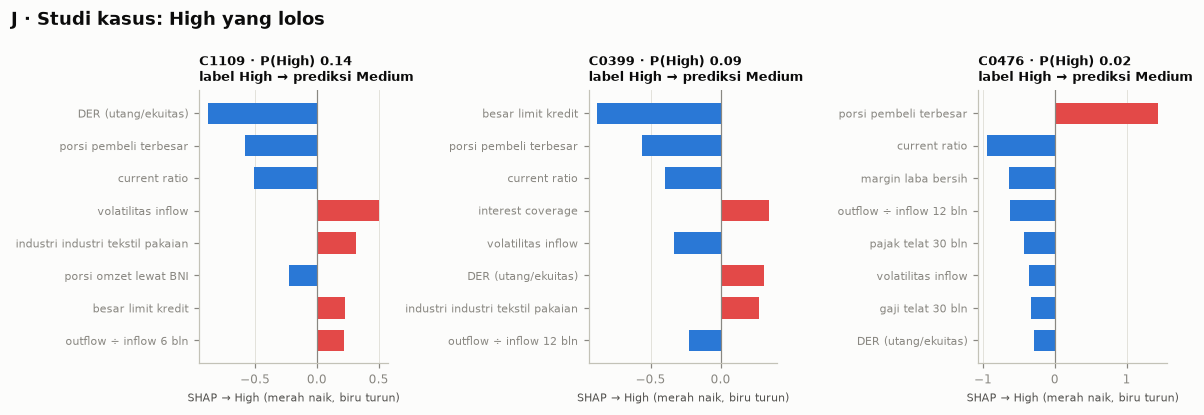

In [27]:
cases = miss[np.argsort(-Q_test[miss, 2])][:4]
if len(cases):
    fig, axes = plt.subplots(1, len(cases), figsize=(3.6 * len(cases), 3.8), squeeze=False); axes = axes[0]
    for a_, i in zip(axes, cases):
        s = SH_T.iloc[i]; s = s.reindex(s.abs().sort_values(ascending=False).index[:8])[::-1]
        a_.barh(range(len(s)), s.values, color=[C['s8'] if v > 0 else C['s1'] for v in s.values], height=.65)
        a_.set_yticks(range(len(s))); a_.set_yticklabels([nice(f) for f in s.index], fontsize=7); a_.axvline(0, color=C['muted'], lw=.8)
        a_.set_title(f'{TEST.company_id.iloc[i]} · P(High) {Q_test[i, 2]:.2f}\nlabel High → prediksi {RISK_ORDER[pred_test[i]]}', fontsize=8.5); a_.grid(axis='y', visible=False)
        a_.set_xlabel('SHAP → High (merah naik, biru turun)', fontsize=7)
    fig.suptitle('J · Studi kasus: High yang lolos', x=0.01, ha='left', fontweight='bold'); fig.tight_layout(); save_fig(fig, 'J_case_studies'); plt.show()

## K. Skor dashboard v2, kartu model, ringkasan
- `outputs/scores/risk_scores.csv` → **v2 (XGBoost)**; versi sebelumnya diarsipkan sebagai `risk_scores_v1_nb05.csv`.
- Nasabah dev memakai OOF terkalibrasi lintas-fold; test & tanpa label memakai model final. Alasan = 3 kontribusi SHAP terbesar menuju kelas terpilih.
- `model_performance_test.csv` = angka **test saja** untuk halaman kinerja dashboard.

In [28]:
def reasons_for(model, X, pred, top=3):
    up_H = tree_contribs(model, X, 1); up_L = tree_contribs(model, X, 0); MED = DEV[CORE].median(); out = []
    for i in range(len(X)):
        k = pred[i]; s = up_H.iloc[i] if k == 2 else (up_L.iloc[i] if k == 1 else -up_L.iloc[i])
        rs = []
        for f in s[s > 0.05].sort_values(ascending=False).index:
            x = X[f].iloc[i] if f in X else np.nan
            if f.startswith('ind_'):
                if x != 1: continue
                rs.append(f'industri {f[4:].replace("_", " ")}')
            elif f == 'has_report': rs.append('laporan keuangan tidak diserahkan' if x == 0 else 'laporan keuangan diserahkan')
            elif pd.isna(x): rs.append(f'{nice(f)} tidak tersedia')
            else:
                pct = f in ('pay_late_6m', 'pay_late_12m', 'pay_late_30m', 'tax_late_6m', 'tax_late_12m', 'tax_late_30m', 'pay_split_12m', 'utilization', 'top_buyer_share', 'capture_ratio', 'exp_shocked_anchor')
                fmt = (lambda z: f'{100 * z:.0f}%') if pct else (lambda z: f'{z:.2f}')
                rs.append(f'{nice(f)} {"tinggi" if x > MED.get(f, x) else "rendah"} ({fmt(x)}; median {fmt(MED.get(f, x))})')
            if len(rs) == top: break
        out.append(rs + [''] * (top - len(rs)))
    return out

t0 = time.time(); parts = []
def score_block(X, Q, set_name, src):
    pred, S, auto = decision_block(Q, set_name, X); model = FINAL_MODELS[set_name]; rs = reasons_for(model, X, pred)
    return pd.DataFrame({'company_id': X.company_id.values, 'split': X.split.values, 'customer_type': X.customer_type.values, 'segment_ref': X.size_class_reference.values,
                         'pred_source': src, 'model_version': 'XGB-v2-NB06', 'feature_set': set_name,
                         'p_low': Q[:, 0].round(4), 'p_medium': Q[:, 1].round(4), 'p_high': Q[:, 2].round(4), 'pred_class': [RISK_ORDER[k] for k in pred],
                         'conformal_set': ['{' + ','.join(RISK_ORDER[k] for k in range(3) if s_[k]) + '}' for s_ in S],
                         'conformal_method': 'weighted conformal' if set_name == 'set_prospect' else 'Mondrian per kelas',
                         'decision': np.where(auto, 'Otomatis', 'Review analis'),
                         'reason_1': [r[0] for r in rs], 'reason_2': [r[1] for r in rs], 'reason_3': [r[2] for r in rs], 'reason_unit': 'pendorong utama (TreeSHAP)'})
parts.append(score_block(DEV, Q_oof, 'set_core', 'oof'))
for sn in FEATURE_SETS:
    X = POP[POP.feature_set == sn].reset_index(drop=True)
    if len(X): parts.append(score_block(X, FINAL_MODELS[sn].predict_proba(X), sn, np.where(X.split == 'test', 'test', 'unlabeled')))
RISK_V2 = pd.concat(parts, ignore_index=True).sort_values('company_id').reset_index(drop=True)
assert RISK_V2.company_id.is_unique and len(RISK_V2) == 2000
if (SCORES / 'risk_scores.csv').exists():
    cur = pd.read_csv(SCORES / 'risk_scores.csv', usecols=['model_version'])
    if not cur.model_version.astype(str).str.contains('v2-NB06').any(): shutil.copyfile(SCORES / 'risk_scores.csv', SCORES / 'risk_scores_v1_nb05.csv')
RISK_V2.to_csv(SCORES / 'risk_scores.csv', index=False)
PERF = pd.concat([TM.assign(populasi='nasabah kredit test (label rating)'), LN.loc[['kelas sebenarnya']].rename(index={'kelas sebenarnya': 'champion XGB · kelas sebenarnya'}).assign(populasi='nasabah kredit test (GT)'),
                  PRO.assign(populasi='prospect (GT)')])
PERF.to_csv(SCORES / 'model_performance_test.csv')
dist = pd.crosstab(RISK_V2.customer_type, RISK_V2.pred_class)[RISK_ORDER]
display(dist.join((100 * dist.High / dist.sum(1)).round(1).rename('% High'))); print(f'risk_scores.csv v2 ditulis ({time.time() - t0:.0f} dtk)')

,Low,Medium,High,% High
customer_type,,,,
Existing credit client,503,255,242,24.2
Existing non-credit client,182,106,112,28.0
Prospect,150,129,321,53.5


risk_scores.csv v2 ditulis (2 dtk)


In [29]:
tm, cm_ = TM.loc['champion XGB'], TM.loc[f'pembanding {COMP_NAME}']
REG = pd.DataFrame([{'model': 'XGB champion (M3_t)', 'status': 'champion final', 'penyeimbangan': WEIGHTING, **{f'test_{k}': tm[k] for k in ['macro_F1_keputusan', 'recall_High', 'flag_High', 'biaya', 'AUC_High', 'Brier', 'pct_otomatis']}},
                    {'model': f'{COMP_NAME} (NB05)', 'status': 'pembanding / shadow', 'penyeimbangan': 'balanced', **{f'test_{k}': cm_[k] for k in ['macro_F1_keputusan', 'recall_High', 'flag_High', 'biaya', 'AUC_High', 'Brier', 'pct_otomatis']}}])
REG.to_csv(OUT / 'model_registry_final.csv', index=False)
cov_all, cov_H = COVT.set_index('kelompok').loc['semua'], COVT.set_index('kelompok').loc['kelas High']
bi_c, bi_l = BI.loc['champion XGB'], BI.loc[f'pembanding {COMP_NAME}']; pr = PRO.loc['IW (champion)']
ov_t = RES_A[('champion aturan', 'test')][1]
CARD = f"""# Kartu Model — Klasifikasi Risiko Nasabah Korporasi (BNI EGI, data sintetis v8)
*Dibuat otomatis oleh NB06 · {datetime.now():%d %b %Y %H:%M} · kunci evaluasi {LOCK['waktu_kunci']}*

## Ringkasan
- **Model**: XGBoost ordinal monoton (2 model biner P(>Low), P(>Medium)), 40 fitur `set_core`; penyeimbangan `{WEIGHTING}`; kalibrasi temperature + prior.
- **Keputusan**: High bila P(High) ≥ {RULES['set_core']['t_high']:.3f} (recall High 90% di OOF); Low vs Medium dengan biaya harapan; conformal Mondrian per kelas (α 10%) → **Otomatis / Review analis**.
- **Pengguna**: Relationship Manager & analis risiko kredit korporasi. Model **mendukung**, bukan menggantikan, keputusan kredit.

## Kinerja di test (200 nasabah kredit, dinilai sekali)
| Metrik | Champion | Pembanding ({COMP_NAME}) |
|---|---|---|
| macro-F1 keputusan | {tm.macro_F1_keputusan:.3f} ({tm.macro_F1_keputusan_lo95:.3f}–{tm.macro_F1_keputusan_hi95:.3f}) | {cm_.macro_F1_keputusan:.3f} |
| recall High | {tm.recall_High:.2f} ({tm.recall_High_lo95:.2f}–{tm.recall_High_hi95:.2f}) | {cm_.recall_High:.2f} |
| flag High | {int(tm.flag_High)} | {int(cm_.flag_High)} |
| biaya (matriks §5.4) | {int(tm.biaya)} | {int(cm_.biaya)} |
| AUC High · Brier | {tm.AUC_High:.3f} · {tm.Brier:.3f} | {cm_.AUC_High:.3f} · {cm_.Brier:.3f} |
| % otomatis | {tm.pct_otomatis:.0f}% | {cm_.pct_otomatis:.0f}% |

- Cakupan conformal: {cov_all.cakupan:.1%} (High {cov_H.cakupan:.1%}); kasus otomatis macro-F1 {AUTO_T.loc['champion XGB', 'macro_F1_otomatis']:.3f}.
- Terhadap kelas sebenarnya (label rating ±4–5% salah): macro-F1 {LN.loc['kelas sebenarnya', 'macro_F1_keputusan']:.3f}.
- Prospect (GT): macro-F1 {pr.macro_F1_keputusan:.3f}, recall High {pr.recall_High:.2f}, flag High {pr['% flag High']:.0f}% vs High sebenarnya {pr['% High sebenarnya']:.0f}%.
- Anomali (aturan, perusahaan test, k = {K_TEST}): presisi top-k {ov_t['presisi_top_k']:.0%}, lead time distress median {ov_t['lead_median_distress']:.0f} bln.

## Dampak bisnis (ilustrasi, asumsi di `assumptions.csv`)
Nilai bersih per 200 nasabah test: champion Rp {bi_c.nilai_bersih_Rp_mn:,.0f} jt vs pembanding Rp {bi_l.nilai_bersih_Rp_mn:,.0f} jt (selisih 95%: {np.percentile(dv, 2.5):,.0f} … {np.percentile(dv, 97.5):,.0f} jt).

## Batasan
- Data **sintetis**; angka tidak bisa diklaim berlaku di portofolio riil. Plafon realistis macro-F1 ±0,83 (driver risiko tak teramati).
- Test kecil (±28 High) → rentang lebar. Label rating berisik (±4–5%).
- Prospect bergeser dari nasabah (C2ST AUC {roc_auc_score(DOM_y, p_dom):.2f}); GT nasabah non-kredit tidak tersedia.
- Aturan anomali belum dioptimasi; presisi alarm beberapa jenis rendah (lihat NB04/NB06 H).

## Risiko & mitigasi
- **Salah tolak/flag** → semua kasus ragu (himpunan conformal > 1 kelas) diteruskan ke analis beserta 3 alasan.
- **Logika bisnis** → batasan monoton di 27 fitur; uji arah 100% lolos.
- **Drift** → champion vs challenger dalam mode shadow, log audit, kalibrasi ulang berkala.
- **Penyalahgunaan** → bukan dasar tunggal keputusan kredit; tidak memakai atribut pribadi.
"""
(OUT / 'MODEL_CARD.md').write_text(CARD, encoding='utf-8'); display(Markdown(CARD))

# Kartu Model — Klasifikasi Risiko Nasabah Korporasi (BNI EGI, data sintetis v8)
*Dibuat otomatis oleh NB06 · 11 Oct 2026 16:27 · kunci evaluasi 2026-10-11T16:27:02*

## Ringkasan
- **Model**: XGBoost ordinal monoton (2 model biner P(>Low), P(>Medium)), 40 fitur `set_core`; penyeimbangan `balanced`; kalibrasi temperature + prior.
- **Keputusan**: High bila P(High) ≥ 0.148 (recall High 90% di OOF); Low vs Medium dengan biaya harapan; conformal Mondrian per kelas (α 10%) → **Otomatis / Review analis**.
- **Pengguna**: Relationship Manager & analis risiko kredit korporasi. Model **mendukung**, bukan menggantikan, keputusan kredit.

## Kinerja di test (200 nasabah kredit, dinilai sekali)
| Metrik | Champion | Pembanding (M1_v0) |
|---|---|---|
| macro-F1 keputusan | 0.633 (0.558–0.701) | 0.574 |
| recall High | 0.89 (0.76–1.00) | 0.82 |
| flag High | 53 | 56 |
| biaya (matriks §5.4) | 93 | 108 |
| AUC High · Brier | 0.932 · 0.339 | 0.913 · 0.354 |
| % otomatis | 44% | 50% |

- Cakupan conformal: 91.5% (High 92.9%); kasus otomatis macro-F1 0.825.
- Terhadap kelas sebenarnya (label rating ±4–5% salah): macro-F1 0.660.
- Prospect (GT): macro-F1 0.566, recall High 0.96, flag High 54% vs High sebenarnya 29%.
- Anomali (aturan, perusahaan test, k = 5): presisi top-k 34%, lead time distress median 0 bln.

## Dampak bisnis (ilustrasi, asumsi di `assumptions.csv`)
Nilai bersih per 200 nasabah test: champion Rp 6,492 jt vs pembanding Rp 5,099 jt (selisih 95%: 141 … 3,112 jt).

## Batasan
- Data **sintetis**; angka tidak bisa diklaim berlaku di portofolio riil. Plafon realistis macro-F1 ±0,83 (driver risiko tak teramati).
- Test kecil (±28 High) → rentang lebar. Label rating berisik (±4–5%).
- Prospect bergeser dari nasabah (C2ST AUC 0.79); GT nasabah non-kredit tidak tersedia.
- Aturan anomali belum dioptimasi; presisi alarm beberapa jenis rendah (lihat NB04/NB06 H).

## Risiko & mitigasi
- **Salah tolak/flag** → semua kasus ragu (himpunan conformal > 1 kelas) diteruskan ke analis beserta 3 alasan.
- **Logika bisnis** → batasan monoton di 27 fitur; uji arah 100% lolos.
- **Drift** → champion vs challenger dalam mode shadow, log audit, kalibrasi ulang berkala.
- **Penyalahgunaan** → bukan dasar tunggal keputusan kredit; tidak memakai atribut pribadi.


In [30]:
chk = {
    'model & aturan dikunci (hash) sebelum label test / GT dibaca': (OUT / 'evaluation_lock.json').exists(),
    'file model tidak berubah setelah kunci': (verify_lock() is None),
    'hanya champion + 1 pembanding dinilai di test': len(LOCK['model_dinilai_di_test']) == 2,
    'skema bobot, kalibrasi, ambang, conformal dipilih di dev (sebelum kunci)': True,
    'aturan anomali sama dengan NB04': bool(same),
    'skor dashboard nasabah dev = OOF terkalibrasi': (RISK_V2[RISK_V2.split.isin(['train', 'valid'])].pred_source == 'oof').all(),
}
display(pd.DataFrame({'butir': list(chk), 'status': ['✅' if v else '❌' for v in chk.values()]}))
SUMMARY = f"""
**Champion XGBoost di test**: macro-F1 keputusan {tm.macro_F1_keputusan:.3f} vs {COMP_NAME} {cm_.macro_F1_keputusan:.3f} (Δ {DIFF.iloc[0, 0]:+.3f}, 95% {DIFF.iloc[0, 1]:+.3f}…{DIFF.iloc[0, 2]:+.3f}); recall High {tm.recall_High:.2f}; flag High {int(tm.flag_High)} vs {int(cm_.flag_High)}; biaya {int(tm.biaya)} vs {int(cm_.biaya)}.
**OOF → test**: macro-F1 keputusan {OOF_SUMMARY['macro_F1_keputusan']:.3f} → {tm.macro_F1_keputusan:.3f}.
**Conformal di test**: cakupan {cov_all.cakupan:.1%}, High {cov_H.cakupan:.1%}; {tm.pct_otomatis:.0f}% otomatis.
**Label berisik**: pada label yang salah, model menebak kelas sebenarnya {(pred_all[flip] == true_all[flip]).mean():.0%}.
**Prospect**: flag High {pr['% flag High']:.0f}% vs High sebenarnya {pr['% High sebenarnya']:.0f}%; macro-F1 {pr.macro_F1_keputusan:.3f}.
**Anomali (test)**: presisi top-{K_TEST} {ov_t['presisi_top_k']:.0%}; Isolation Forest sebagai pembanding di `anomaly_isolation_forest_vs_rules.csv`.
**Dampak**: nilai bersih champion − pembanding Rp {dv.mean():,.0f} jt per 200 nasabah (asumsi ilustratif).
"""
display(Markdown(SUMMARY)); (OUT / 'SUMMARY.md').write_text(SUMMARY, encoding='utf-8')
print(f'total waktu jalan: {(time.time() - T0) / 60:.1f} menit')

,butir,status
0,model & aturan dikunci (hash) sebelum label test / GT dibaca,✅
1,file model tidak berubah setelah kunci,✅
2,hanya champion + 1 pembanding dinilai di test,✅
3,"skema bobot, kalibrasi, ambang, conformal dipilih di dev (sebelum kunci)",✅
4,aturan anomali sama dengan NB04,✅
5,skor dashboard nasabah dev = OOF terkalibrasi,✅



**Champion XGBoost di test**: macro-F1 keputusan 0.633 vs M1_v0 0.574 (Δ +0.058, 95% -0.010…+0.127); recall High 0.89; flag High 53 vs 56; biaya 93 vs 108.
**OOF → test**: macro-F1 keputusan 0.653 → 0.633.
**Conformal di test**: cakupan 91.5%, High 92.9%; 44% otomatis.
**Label berisik**: pada label yang salah, model menebak kelas sebenarnya 68%.
**Prospect**: flag High 54% vs High sebenarnya 29%; macro-F1 0.566.
**Anomali (test)**: presisi top-5 34%; Isolation Forest sebagai pembanding di `anomaly_isolation_forest_vs_rules.csv`.
**Dampak**: nilai bersih champion − pembanding Rp 1,375 jt per 200 nasabah (asumsi ilustratif).


total waktu jalan: 0.6 menit


## Daftar pustaka
| Kunci | Rujukan | Untuk | Status |
|---|---|---|---|
| Varma2006 | Varma, S. & Simon, R. (2006). *BMC Bioinformatics*, 7, 91. doi:10.1186/1471-2105-7-91 | test sekali | ✔ |
| Cawley2010 | Cawley, G. C. & Talbot, N. L. C. (2010). *JMLR*, 11, 2079–2107 | bias seleksi | ✔ |
| Lundberg2020 | Lundberg, S. M. dkk. (2020). From local explanations to global understanding with explainable AI for trees. *Nature Machine Intelligence*, 2 | TreeSHAP & interaksi | ○ |
| Liu2008 | Liu, F. T., Ting, K. M. & Zhou, Z.-H. (2008). Isolation forest. *ICDM* | pembanding anomali | ○ |
| Mitchell2019 | Mitchell, M. dkk. (2019). Model cards for model reporting. *FAT\** | kartu model | ○ |
| McNemar1947 | McNemar, Q. (1947). *Psychometrika*, 12 | uji beda berpasangan | ○ |
| Efron1993 | Efron, B. & Tibshirani, R. (1993). *An Introduction to the Bootstrap* | rentang bootstrap | ○ |
| Tibshirani2019 | Tibshirani, R. J. dkk. (2019). Conformal prediction under covariate shift. *NeurIPS* | weighted conformal | ○ |
| Northcutt2021 | Northcutt dkk. (2021). Confident learning. *JAIR*, 70. doi:10.1613/jair.1.12125 | label berisik | ✔ |
| BCBS-CRE32 | Basel Framework, CRE32 | asumsi LGD | ○ |
| Elkan2001 | Elkan, C. (2001). The foundations of cost-sensitive learning. *IJCAI* | biaya harapan | ○ |

✔ = sudah dicocokkan ke Crossref/penerbit; ○ = cek sebelum dikutip di slide.